# Apprendre l'allocation de Markowitz avec un réseau de neurones

**Auteurs : Ilan Mellul, Nathan Bounhoure, Omar Guenoun, Félix Bouvier**

**Projet 4 : M2 ISF, Gestion des risques.** Peut-on apprendre, à partir de l'information disponible à la date $t$, le portefeuille qui *sera* optimal sur les 63 jours suivants ?

| | Partie | Durée |
|---|---|---|
| 1 | Données, features et cible | 3 min |
| 2 | Protocole commun (validation croisée, métriques) et référence k-NN | 3 min |
| 3 | Trois familles de réseaux : MLP, U-Net, récurrents | 5 min |
| 4 | Backtest, interprétation (SHAP) et conclusion | 4 min |

**Principe du notebook : tout est commun.** Un seul chargement des données, une seule normalisation, une seule boucle d'entraînement, une seule validation croisée et une seule fonction d'évaluation, utilisés par tous les modèles. Seule l'architecture change.

In [1]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from scipy.optimize import minimize
from scipy.spatial.distance import cdist
from sklearn.covariance import LedoitWolf

DATA, RES, N = Path("data/processed/N63_wmax1"), Path("synthesis/resultats_final"), 63    # N : horizon de la cible, en jours
CKPT = RES / "checkpoints"          # modèles entraînés : validation croisée et modèles finaux
CKPT.mkdir(parents=True, exist_ok=True)
RERUN = False       # False : relit ce qui est déjà dans RES et ne calcule que ce qui manque (reprise possible après une interruption)
                    # True : recalcule tout et écrase. Lancement complet : dossier RES vide et RERUN = False.

## 1. Données, features et cible

**Univers** : 15 actions du CAC 40 (tous secteurs) + un actif **CASH** rémunéré à l'Euribor 3 mois, en données quotidiennes de 2005 à 2025 (Yahoo Finance, FRED, BCE). Le jeu de données est produit une fois pour toute l'équipe par `data_generation/build_dataset.py`.

**Features $X_t$ : 160 variables, toutes calculées sur des fenêtres qui finissent en $t$** (aucune information future).

| Famille | Variables | Nombre |
|---|---|---|
| Par action (×15) | momentum 5, 21, 63, 126, 252 j ; volatilité 21 et 63 j ; volatilité baissière ; drawdown 1 an ; corrélation au CAC | 150 |
| Structure du marché | 3 premières valeurs propres de la matrice de corrélation ; momentum et volatilité du CAC | 5 |
| Macro | VIX et sa variation, pente des taux US, spread de crédit, Euribor 3M | 5 |

**Contrôle qualité** : un test automatique sur les prix (cours figés ou arrondis) nous a fait remplacer AXA, dont l'historique Yahoo était arrondi à l'euro avant 2008, par Société Générale.

In [2]:
def lire(fichier):
    """Lit un fichier CSV dont la première colonne contient les dates."""
    return pd.read_csv(fichier, index_col=0, parse_dates=True)

X = lire(DATA / "X.csv")                  # les 160 features de chaque date
Y = lire(DATA / "Y.csv")                  # la cible : les 16 poids de l'oracle
R_fwd = lire(DATA / "R_fwd.csv")          # rendement de chaque actif sur les 63 jours suivants
meta = lire(DATA / "meta.csv")            # fin de la fenêtre de la cible, découpage train / val / test
rets = lire(DATA / "returns.csv")         # rendements quotidiens des 15 actions
ASSETS, TICKERS = list(Y.columns), list(Y.columns[:-1])
Yn = Y.to_numpy()
pos = rets.index.get_indexer(X.index)                 # position de chaque date t dans le calendrier de bourse

# rendements quotidiens des 16 actifs : le CASH rapporte l'Euribor 3M connu la veille
px = lire("data/raw/prices.csv").dropna(how="all").ffill(limit=2).dropna(how="any")
macro = lire("data/raw/macro.csv")
macro = macro.reindex(px.index.union(macro.index)).ffill().reindex(px.index).shift(1)
rf_day = (macro["EURIBOR3M"] / 100 / 252).reindex(rets.index).fillna(0).to_numpy()
R_day = np.column_stack([rets.to_numpy(), rf_day])

print(f"X {X.shape} | Y {Y.shape} | {X.index[0].date()} → {X.index[-1].date()}")
print(f"Avant 2020 : {(X.index < '2020').sum()} dates, soit seulement ≈ {(X.index < '2020').sum() // N} trimestres sans chevauchement")

X (5082, 160) | Y (5082, 16) | 2005-11-21 → 2025-09-30
Avant 2020 : 3608 dates, soit seulement ≈ 57 trimestres sans chevauchement


### La cible : l'oracle de Markowitz

Pour chaque date $t$, la cible $Y_t$ est le portefeuille **long-only de Sharpe maximal sur les 63 jours suivants** ($t+1$ à $t+63$) :

$$Y_t=\arg\max_{w\ge 0,\ \sum w=1}\ \frac{w^\top\mu}{\sqrt{w^\top\Sigma\,w}}\qquad \mu:\ \text{rendement moyen en excès du CASH},\quad \Sigma:\ \text{covariance (Ledoit-Wolf)}$$

Si aucune action ne bat le taux sans risque sur la période, l'oracle vaut 100 % CASH. C'est un **oracle** : il connaît le futur. Le modèle doit s'en approcher avec la seule information disponible en $t$.

Écart maximal avec Y.csv le 2015-06-01 : 0.0000
L'oracle détient en moyenne 2.9 actifs effectifs (sur 16), est 100 % CASH 2.4% du temps et change 86% du portefeuille d'un trimestre au suivant.


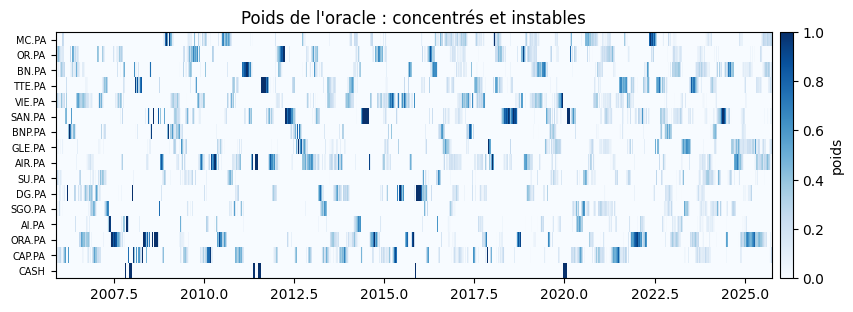

In [3]:
def max_sharpe(win, rf_win):
    # Portefeuille long-only de Sharpe maximal sur une fenêtre de rendements quotidiens (jours × 15 actions).
    mu = (win - rf_win[:, None]).mean(0) * 252
    if mu.max() <= 0:                                           # aucune action ne bat le CASH
        return np.append(np.zeros(15), 1.0)
    S = LedoitWolf().fit(win).covariance_ * 252
    y0 = np.eye(15)[mu.argmax()] / mu.max()                     # point de départ admissible
    # forme équivalente : minimiser la variance y'Sy sous la contrainte mu'y = 1, y >= 0, puis w = y / somme(y)
    def variance(y):
        return y @ S @ y
    def gradient_variance(y):
        return 2 * S @ y
    def contrainte(y):
        return mu @ y - 1
    def gradient_contrainte(y):
        return mu
    res = minimize(variance, y0, jac=gradient_variance, bounds=[(0, None)] * 15, method="SLSQP",
                   constraints={"type": "eq", "fun": contrainte, "jac": gradient_contrainte})
    return np.append(res.x / res.x.sum(), 0.0)

# Vérification : on recalcule la cible d'une date à partir des 63 jours qui la suivent
t = X.index.get_loc("2015-06-01")
p = pos[t]
w = max_sharpe(R_day[p + 1:p + N + 1, :15], rf_day[p + 1:p + N + 1])
print(f"Écart maximal avec Y.csv le {X.index[t].date()} : {np.abs(w - Yn[t]).max():.4f}")

print(f"L'oracle détient en moyenne {(1 / (Yn ** 2).sum(1)).mean():.1f} actifs effectifs (sur 16), "
      f"est 100 % CASH {(Yn[:, -1] == 1).mean():.1%} du temps "
      f"et change {np.abs(Yn[N:] - Yn[:-N]).sum(1).mean() / 2:.0%} du portefeuille d'un trimestre au suivant.")

fig, ax = plt.subplots(figsize=(11, 3.2))
im = ax.imshow(Yn.T, aspect="auto", cmap="Blues", vmin=0, vmax=1, interpolation="nearest",
               extent=[X.index[0].year + X.index[0].dayofyear / 365, X.index[-1].year + X.index[-1].dayofyear / 365, 16, 0])
ax.set_yticks(np.arange(16) + 0.5, ASSETS, fontsize=7)
ax.set_title("Poids de l'oracle : concentrés et instables")
fig.colorbar(im, ax=ax, label="poids", pad=0.01)
plt.show()

### Un seul prétraitement pour tous les modèles

Chaque famille de modèles lit la même information sous une forme différente. Toutes les entrées sont construites ici, et **normalisées par une seule fonction, avec les statistiques du train uniquement** (recalculées à chaque pli de validation croisée, pour ne jamais utiliser le futur).

| Entrée | Forme | Utilisée par |
|---|---|---|
| `tab` : les 160 features | (dates, 160) | k-NN, MLP (choix de la perte et des variables) |
| `tab_10` : les 10 variables globales (structure du marché et macro), construites en partie 3 | (dates, 10) | k-NN (ablation), MLP final |
| `seq_j` : 60 rendements journaliers des 15 actions | (dates, 60, 15) | U-Net, LSTM global |
| `seq_h` : 52 rendements hebdomadaires par action (canal 1) + ceux du CAC (canal 2) | (dates, 15, 52, 2) | LSTM partagé, Transformer |

In [4]:
logr, log_cac = np.log1p(rets.to_numpy()), np.log1p(px["^FCHI"].pct_change().iloc[1:].to_numpy())

def weekly(lr, n_weeks=52, step=5):
    """Pour chaque date t : les 52 rendements log hebdomadaires (semaines de 5 jours de bourse) qui finissent en t."""
    cumul = np.concatenate([np.zeros((1,) + lr.shape[1:]), lr.cumsum(axis=0)])   # cumul[j] = somme des j premiers rendements
    resultat = np.zeros((len(pos), n_weeks) + lr.shape[1:])
    for k, i in enumerate(pos):                       # i : position de la date t dans le calendrier
        for w in range(n_weeks):                      # w = 0 : la semaine la plus ancienne ; 51 : celle qui finit en t
            fin = i + 1 - step * (n_weeks - 1 - w)
            debut = fin - step
            if debut >= 0:                            # semaine entièrement dans l'historique (sinon 0)
                resultat[k, w] = cumul[fin] - cumul[debut]   # somme des 5 rendements quotidiens de la semaine
    return resultat

fenetres_60j = []
for i in pos:
    fenetres_60j.append(logr[i - 59:i + 1])                          # les 60 derniers rendements quotidiens des 15 actions
hebdo_actions = weekly(logr).transpose(0, 2, 1)                       # (dates, 15 actions, 52 semaines)
hebdo_cac = np.repeat(weekly(log_cac)[:, None, :], 15, axis=1)        # le même CAC recopié pour les 15 actions

RAW = {"tab": X.to_numpy(),                                           # (dates, 160)
       "seq_j": np.stack(fenetres_60j),                               # (dates, 60, 15)
       "seq_h": np.stack([hebdo_actions, hebdo_cac], axis=-1)}        # (dates, 15, 52, 2) : canal 0 action, canal 1 CAC
STAT_AXES = {"tab": 0, "seq_j": None, "seq_h": (0, 1, 2)}     # features : par colonne ; séquences : une seule échelle par canal

def prepare(names, tr_i):
    # Entrées normalisées avec les statistiques des dates d'entraînement tr_i uniquement.
    out = []
    for n in names:
        a, ax = RAW[n], STAT_AXES[n]
        if n.startswith("tab"):                      # features : centrées-réduites
            mean = a[tr_i].mean(axis=ax)
        else:                                        # rendements : déjà centrés, on ne change que l'échelle
            mean = 0
        out.append(((a - mean) / a[tr_i].std(axis=ax)).astype(np.float32))
    return out

print({n: a.shape for n, a in RAW.items()})

{'tab': (5082, 160), 'seq_j': (5082, 60, 15), 'seq_h': (5082, 15, 52, 2)}


## 2. Protocole commun

Les cibles de deux jours voisins se chevauchent sur 62 jours : nos ~3 500 dates d'entraînement ne valent qu'une **cinquantaine de trimestres indépendants**. Le protocole est donc fixé à l'avance et identique pour tous les modèles.

**A. Sélection (2006–2019) : validation croisée *walk-forward* à 4 plis.** On entraîne sur tout le passé et on valide sur les 2 années suivantes (2012–13, 2014–15, 2016–17, 2018–19). **Purge** : une date n'entre dans le train que si sa cible se termine avant le début de la validation.

**B. Évaluation finale (2020–2025), une seule fois.** La configuration retenue est réentraînée sur 2006–2019, pendant le nombre d'époques trouvé en validation croisée, puis backtestée sur le test.

**Une seule fonction d'évaluation**, pour les modèles comme pour les références :
- **entropie croisée** avec l'oracle : la qualité de l'imitation (c'est aussi la perte d'entraînement) ;
- **backtest quotidien** : on achète les poids prédits, on les laisse dériver avec les prix, on rééquilibre tous les 63 jours avec **0,1 % de frais** sur les montants échangés. Comme le résultat dépend du jour de départ, on simule les 63 calendriers possibles et on fait la moyenne. On en tire le **Sharpe** (en excès du CASH ; `sharpe_std` mesure sa sensibilité au jour de départ), le rendement, la perte maximale et le **turnover** (part du portefeuille échangée par an) ;
- **nombre effectif d'actifs** $1/\sum_i w_i^2$ : la concentration du portefeuille.

### 2.1 Les périodes

Pour chaque période, on sépare les dates d'entraînement et les dates d'évaluation. Purge : une date n'entre dans l'entraînement que si ses 63 jours futurs se terminent avant le début de l'évaluation.

In [5]:
label_end = pd.to_datetime(meta["label_end"])      # dernier jour des 63 jours futurs utilisés par Y_t

def purged_train(before):
    """Dates depuis 2006 dont la cible est entièrement connue avant `before` (purge)."""
    garder = (X.index >= "2006-01-01") & (label_end < pd.Timestamp(before))
    return np.flatnonzero(garder.to_numpy())

# 4 validations de 2 ans : on entraîne sur tout le passé, on évalue sur les 2 années suivantes
FOLDS = {}
for y0 in [2012, 2014, 2016, 2018]:
    garder = (X.index >= f"{y0}-01-01") & (label_end < pd.Timestamp(f"{y0 + 2}-01-01"))
    FOLDS[f"{y0}-{y0 + 1}"] = (purged_train(f"{y0}-01-01"), np.flatnonzero(garder.to_numpy()))

# Test final : entraînement sur 2006–2019, évaluation sur 2020–2025
FINAL = (purged_train("2020-01-01"), np.flatnonzero(meta["split"].to_numpy() == "test"))

periodes = dict(FOLDS)
periodes["test final"] = FINAL
for name, (tr, va) in periodes.items():
    print(f"{name:10s} : train {len(tr):4d} dates (→ {X.index[tr[-1]].date()}) | "
          f"évaluation {len(va):4d} dates ({X.index[va[0]].date()} → {X.index[va[-1]].date()})")

2012-2013  : train 1472 dates (→ 2011-10-03) | évaluation  446 dates (2012-01-02 → 2013-10-01)
2014-2015  : train 1981 dates (→ 2013-10-01) | évaluation  448 dates (2014-01-02 → 2015-10-01)
2016-2017  : train 2492 dates (→ 2015-10-01) | évaluation  449 dates (2016-01-04 → 2017-09-29)
2018-2019  : train 3004 dates (→ 2017-09-29) | évaluation  448 dates (2018-01-02 → 2019-10-02)
test final : train 3515 dates (→ 2019-10-02) | évaluation 1474 dates (2020-01-02 → 2025-09-30)


### 2.2 Le juge

On simule d'abord **un** portefeuille : on achète les poids prédits, ils dérivent avec les prix, et on revient aux nouveaux poids prédits tous les 63 jours (0,1 % de frais). Le résultat dépend du jour du premier rééquilibrage : on simule les 63 possibilités et on fait la moyenne.

In [6]:
def simuler_un_calendrier(W, R_lendemain, decalage, reb=N, cost=1e-3):
    """UN portefeuille : premier rééquilibrage au jour `decalage`, puis tous les `reb` jours."""
    w = W[0].copy()
    rendements, echange_total = [], 0.0
    for d in range(len(W)):
        echange = 0.0
        if d > 0 and d % reb == decalage:                  # jour de rééquilibrage
            echange = np.abs(W[d] - w).sum()               # part du portefeuille vendue + achetée
            w = W[d].copy()
        g = w @ (1 + R_lendemain[d])                       # valeur le lendemain, pour 1 €
        rendements.append(g * (1 - cost * echange) - 1)    # rendement du jour, net de frais
        w = w * (1 + R_lendemain[d]) / g                   # les poids dérivent avec les prix
        echange_total += echange
    return np.array(rendements), echange_total

def evaluate(W, i, reb=N, cost=1e-3):
    """Moyenne des mesures sur les 63 calendriers. W : poids décidés à la clôture de chaque date de i."""
    R_lendemain, rf = R_day[pos[i] + 1], rf_day[pos[i] + 1]   # rendements du jour suivant chaque décision

    # 1. les 63 simulations (une colonne par calendrier)
    rendements_calendriers, echanges_calendriers = [], []
    for k in range(reb):
        rendements, echange = simuler_un_calendrier(W, R_lendemain, k, reb, cost)
        rendements_calendriers.append(rendements)
        echanges_calendriers.append(echange)
    daily = np.column_stack(rendements_calendriers)
    traded = np.array(echanges_calendriers)

    # 2. mesures de chaque calendrier
    wealth, years = (1 + daily).cumprod(0), len(i) / 252
    sharpe = (daily - rf[:, None]).mean(0) / daily.std(0) * np.sqrt(252)

    # 3. moyenne sur les calendriers
    stats = {"ce": -(Yn[i] * np.log(W + 1e-8)).sum(1).mean(),          # écart avec l'oracle
             "sharpe": sharpe.mean(), "sharpe_std": sharpe.std(),        # + sensibilité au calendrier
             "rdt_ann": (wealth[-1] ** (1 / years) - 1).mean(),
             "perte_max": (wealth / np.maximum.accumulate(wealth) - 1).min(0).mean(),
             "turnover_an": traded.mean() / years,
             "n_eff": (1 / (W ** 2).sum(1)).mean()}                     # nombre effectif d'actifs
    return stats, pd.Series(wealth.mean(1), index=X.index[i])

### 2.3 Les références sur les 4 plis

Deux portefeuilles qui n'utilisent aucune feature fixent les seuils à battre : l'**équipondéré** (1/15 par action) pour le Sharpe, et la **moyenne des cibles du train** pour l'entropie croisée (un modèle qui ne fait pas mieux n'a rien appris au-delà de la répartition moyenne). L'**oracle** donne le plafond.

In [7]:
# Portefeuille équipondéré : 1/15 sur chaque action, rien en CASH
EW = np.append(np.full(15, 1 / 15), 0.0)

def references(tr_i, i):
    """Les trois références, sous forme de poids pour chaque date de i (aucune n'utilise les features)."""
    n = len(i)
    return {"Oracle": Yn[i],                                              # le plafond : connaît le futur
            "Équipondéré": np.tile(EW, (n, 1)),                           # même portefeuille chaque jour
            "Moyenne des cibles du train": np.tile(Yn[tr_i].mean(0), (n, 1))}   # allocation moyenne de l'oracle sur le train

# On évalue chaque référence sur chacun des 4 plis, puis on fait la moyenne des 4 plis
lignes = []
for pli, (tr, va) in FOLDS.items():
    for strategie, W in references(tr, va).items():
        mesures, _ = evaluate(W, va)
        lignes.append({"stratégie": strategie, "pli": pli, **mesures})

ref = pd.DataFrame(lignes)
REF_CV = ref.groupby("stratégie", sort=False).mean(numeric_only=True)
REF_CV.round(3)

,ce,sharpe,sharpe_std,rdt_ann,perte_max,turnover_an,n_eff
stratégie,,,,,,,
Oracle,1.044,3.023,0.187,0.762,-0.098,6.588,2.904
Équipondéré,2.726,0.857,0.008,0.156,-0.153,0.242,15.000
Moyenne des cibles du train,2.721,0.898,0.008,0.149,-0.139,0.245,13.446


### 2.4 Une boucle d'entraînement et une validation croisée pour tous les modèles

- **Perte** : entropie croisée $-\sum_i Y_i\log\pi_i$ entre les poids prédits $\pi$ (sortie d'un softmax) et l'oracle $Y$. Elle est minimale quand $\pi = Y$, et son gradient par rapport aux scores est simplement $\pi - Y$. Alternatives proposées par le sujet : la **MSE** et la maximisation directe du **Sharpe** du lot, mises en duel avec l'entropie croisée pour chaque réseau (voir plus bas).
- **Entraînement** : Adam, mini-lots de dates mélangées dans le train, **arrêt anticipé** sur la perte de validation du pli. Le nombre d'époques ainsi trouvé (médiane des 4 plis) est réutilisé tel quel pour l'entraînement final, qui n'a plus de validation.
- **`cross_validate`** applique la même procédure à n'importe quelle liste de configurations : un réseau comme un k-NN.

#### 2.4.1 Les pertes

Ce que le réseau cherche à minimiser : l'écart avec l'oracle (entropie croisée), ou bien « moins le Sharpe » des portefeuilles prédits.

In [8]:
# Les deux pertes possibles. p : poids prédits, y : poids de l'oracle, r : rendements réalisés sur les 63 jours suivants.

def ce_loss(p, y, r):
    """Entropie croisée : petite quand les poids prédits ressemblent à ceux de l'oracle."""
    return -(y * torch.log(p + 1e-8)).sum(1).mean()

def sharpe_loss(p, y, r):
    """Moins le Sharpe du lot : on maximise le Sharpe des portefeuilles prédits (rendement en excès du CASH)."""
    rendement_exces = (p * r).sum(1) - r[:, -1]
    return -rendement_exces.mean() / rendement_exces.std()

LOSSES = {"ce": ce_loss, "sharpe": sharpe_loss}

#### 2.4.2 Duel des pertes : entropie croisée, MSE et Sharpe

Le sujet propose d'entraîner le réseau avec la **MSE** (moyenne des carrés des écarts entre poids prédits et poids de l'oracle), puis en **maximisant directement le Sharpe** des portefeuilles prédits. Nous mettons ces deux pertes en concurrence avec l'**entropie croisée** :
- les poids prédits et l'oracle sont deux **répartitions** (positives, de somme 1) : l'entropie croisée est la mesure standard de l'écart entre deux répartitions (c'est la perte de la classification) ;
- la MSE pousse très peu à corriger les petits poids. Si l'oracle met 30 % sur une action et que le réseau n'y met que 6 %, l'erreur vaut $(0{,}30-0{,}06)^2 \approx 0{,}06$ avec la MSE, contre $-0{,}30\,\ln(0{,}06) \approx 0{,}84$ avec l'entropie croisée. Or presque tous nos poids sont petits (≈ 1/16 ≈ 6 %) ;
- la perte Sharpe vise directement la performance plutôt que l'imitation de l'oracle, mais un Sharpe calculé sur un lot de quelques centaines de dates est très bruité : la direction donnée au réseau change beaucoup d'un lot à l'autre.

**Le duel.** Pour chaque réseau, une configuration (la configuration retenue ; pour le MLP et le U-Net, le réseau de départ, car la perte y est choisie en premier) est aussi entraînée avec la MSE et avec la perte Sharpe (lots de 256 dates), avec exactement le même protocole (mêmes plis, même arrêt anticipé) ; les résultats apparaissent dans le tableau de chaque partie. On garde l'entropie croisée, sauf si une autre perte fait nettement et régulièrement mieux.

In [9]:
def mse_loss(p, y, r):
    """MSE : moyenne des carrés des écarts entre poids prédits et poids de l'oracle."""
    return ((p - y) ** 2).mean()

LOSSES["mse"] = mse_loss            # la perte est maintenant utilisable dans les fiches de réglages

#### 2.4.3 Entraîner un réseau

À chaque époque, on mélange les dates du train, on les parcourt par lots et on corrige le réseau après chaque lot. On s'arrête quand la perte sur la validation ne s'améliore plus depuis `patience` époques, et on garde le meilleur modèle.

In [10]:
# Réglages par défaut, modifiables configuration par configuration
DEFAULTS = dict(loss="ce",          # perte utilisée
                lr=1e-3,            # taux d'apprentissage
                wd=1e-4,            # pénalité sur la taille des poids du réseau
                batch=128,          # nombre de dates par lot
                max_epochs=100,     # nombre maximal de passages sur le train
                patience=5)         # arrêt après 5 époques sans amélioration en validation

# Cibles et rendements à 63 jours, au format PyTorch
Yt = torch.tensor(Yn, dtype=torch.float32)
Rt = torch.tensor(R_fwd.to_numpy(), dtype=torch.float32)

def predict(model, xs, i):
    """Poids prédits par le réseau pour les dates i (calculés par paquets de 512 dates)."""
    model.eval()
    sorties = []
    with torch.no_grad():
        for paquet in torch.as_tensor(i).split(512):
            entrees = [x[paquet] for x in xs]             # les entrées du modèle pour ces dates
            sorties.append(model(*entrees))               # *entrees : le modèle reçoit une ou plusieurs entrées
    return torch.cat(sorties)

def train(cfg, tr_i, va_i=None, epochs=None, seed=0):
    """Entraîne la configuration cfg sur les dates tr_i.
    - avec va_i : arrêt anticipé quand la perte sur va_i ne s'améliore plus ;
    - sans va_i : on fait exactement `epochs` époques."""
    reglages = dict(DEFAULTS)                    # réglages par défaut...
    reglages.update(cfg)                         # ...remplacés par ceux de la configuration
    cfg = reglages
    # Préparation : entrées, perte, réseau et optimiseur
    xs = [torch.tensor(a) for a in prepare(cfg["inputs"], tr_i)]   # entrées normalisées avec les stats de tr_i
    loss_fn = LOSSES[cfg["loss"]]                                 # la perte choisie dans la fiche
    tr_t = torch.as_tensor(tr_i)

    torch.manual_seed(seed)                                         # graine fixée : même départ à chaque lancement
    model = cfg["model"](**cfg["params"])                           # réseau neuf, construit d'après la fiche
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])   # Adam : corrige les poids du réseau après chaque lot

    # seuil d'amélioration à l'échelle de la perte : la MSE (≈ 0,02) est ~100 fois plus petite que l'entropie croisée (≈ 2,7)
    if cfg["loss"] == "mse":
        tol = 1e-6
    else:
        tol = 1e-4
    # meilleure perte de validation, son époque, les poids du réseau à ce moment, époques sans amélioration
    best, best_ep, best_state, wait = np.inf, epochs, None, 0
    for ep in range(1, (epochs or cfg["max_epochs"]) + 1):         # `epochs` époques si fixé, sinon au plus max_epochs
        # 1. une époque : on mélange les dates du train et on les parcourt par lots
        model.train()
        dates_melangees = tr_t[torch.randperm(len(tr_t))]
        for lot in dates_melangees.split(cfg["batch"]):
            entrees = [x[lot] for x in xs]
            loss = loss_fn(model(*entrees), Yt[lot], Rt[lot])        # perte du lot : poids prédits vs cible
            opt.zero_grad()                                         # efface les corrections du lot précédent
            loss.backward()                                         # calcule dans quel sens corriger chaque poids
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)       # limite la taille des pas
            opt.step()                                              # applique la correction

        # 2. arrêt anticipé (seulement si on a des dates de validation)
        if va_i is None:
            continue
        val = loss_fn(predict(model, xs, va_i), Yt[va_i], Rt[va_i]).item()   # perte sur la validation après cette époque
        if val < best - tol:                                       # amélioration : on garde ce modèle
            best, best_ep, wait = val, ep, 0
            best_state = {}
            for nom_param, valeur in model.state_dict().items():
                best_state[nom_param] = valeur.clone()          # copie des poids du meilleur modèle
        else:                                                       # pas d'amélioration
            wait += 1
            if wait >= cfg["patience"]:
                break

    if best_state is not None:                                      # on revient au meilleur modèle
        model.load_state_dict(best_state)
    return model, xs, best_ep          # best_ep : époques du meilleur modèle (leur médiane sur les 4 plis sert à l'entraînement final)

#### 2.4.4 Un modèle → des poids

La même fonction sert à tous les modèles : pour le k-NN, on fait la moyenne des cibles des k dates les plus proches ; pour un réseau, on l'entraîne puis on prédit.

In [11]:
def fit(cfg, tr_i, va_i=None, epochs=None, seed=0, ckpt=None):
    """Réseau ajusté sur tr_i. Si le checkpoint `ckpt` existe, le modèle est relu au lieu d'être réentraîné ;
    sinon il est entraîné puis enregistré. Renvoie (modèle, entrées normalisées, nombre d'époques)."""
    reglages = dict(DEFAULTS)                                       # réglages par défaut...
    reglages.update(cfg)                                            # ...remplacés par ceux de la configuration
    cfg = reglages
    if ckpt is not None and ckpt.exists() and not RERUN:            # déjà entraîné : on relit le modèle enregistré
        sauvegarde = torch.load(ckpt)                               # poids du réseau + nombre d'époques
        model = cfg["model"](**cfg["params"])                       # réseau vide de la même architecture...
        model.load_state_dict(sauvegarde["poids"])                  # ...dans lequel on recharge les poids enregistrés
        xs = [torch.tensor(a) for a in prepare(cfg["inputs"], tr_i)]  # entrées normalisées avec les stats de tr_i, comme dans train
        return model, xs, sauvegarde["epoques"]
    model, xs, ep = train(cfg, tr_i, va_i, epochs, seed)            # sinon : on entraîne (partie 2.4.3)
    if ckpt is not None:                                            # et on enregistre le modèle pour ne pas le réentraîner
        ckpt.parent.mkdir(parents=True, exist_ok=True)
        torch.save({"poids": model.state_dict(), "epoques": ep}, ckpt)
    return model, xs, ep

def fit_predict(cfg, tr_i, te_i, epochs=None, seed=0, ckpt=None):
    """Ajuste un modèle sur les dates tr_i et renvoie (poids prédits sur te_i, nombre d'époques)."""
    # k-NN : moyenne des cibles des k dates du train les plus proches (rien à entraîner)
    if "k" in cfg:
        Z = prepare([cfg.get("inputs", "tab")], tr_i)[0]             # features normalisées (160 par défaut)
        distances = cdist(Z[te_i], Z[tr_i], cfg["metric"])           # (dates à prédire, dates du train)
        voisins = np.argsort(distances, axis=1)[:, :cfg["k"]]        # les k plus proches
        return Yn[tr_i][voisins].mean(1), 0                         # moyenne des allocations oracle des k voisins ; 0 époque

    # Réseau : arrêt anticipé sur te_i si le nombre d'époques n'est pas fixé
    if epochs:                                   # nombre d'époques fixé : pas de validation
        validation = None
    else:                                        # arrêt anticipé sur te_i
        validation = te_i
    model, xs, ep = fit(cfg, tr_i, validation, epochs, seed, ckpt)  # entraîné, ou relu s'il est déjà enregistré
    return predict(model, xs, te_i).numpy(), ep                     # poids prédits sur te_i

#### 2.4.5 La validation croisée

Chaque configuration est évaluée sur les 4 plis avec le même juge ; `summary` fait la moyenne des 4 plis et ajoute les références en bas du tableau.

In [12]:
CONFIGS, CV = {}, {}

def nom_fichier(texte):
    """Nom de configuration → nom de fichier valide (espaces, deux-points, virgules remplacés)."""
    return re.sub(r"[^\w\-]+", "_", texte).strip("_")

def cross_validate(family, verbose=False):
    """Évalue chaque configuration de la famille sur les 4 plis.
    Sauvegarde au fil de l'eau : chaque modèle de pli est enregistré (checkpoint) et le tableau est réécrit
    après chaque configuration ; les configurations déjà présentes dans le fichier sont relues, pas recalculées."""
    f = RES / f"cv_{family}.csv"
    tableaux, deja_fait = [], set()
    if f.exists() and not RERUN:                                         # résultats déjà calculés
        tableaux.append(pd.read_csv(f))
        deja_fait = set(tableaux[0]["config"])

    for name, cfg in CONFIGS[family].items():
        if name in deja_fait:
            continue
        rows = []
        for fold, (tr_i, va_i) in FOLDS.items():
            if "k" in cfg:                                               # k-NN : rien à enregistrer
                ckpt = None
            else:
                ckpt = CKPT / "cv" / family / f"{nom_fichier(name)}__{fold}.pt"
            W, ep = fit_predict(cfg, tr_i, va_i, ckpt=ckpt)
            mesures, _ = evaluate(W, va_i)
            rows.append({"config": name, "pli": fold, "époques": ep, **mesures})
            if verbose:
                print(f"{name} | pli {fold} | CE {mesures['ce']:.3f} | Sharpe {mesures['sharpe']:.2f} | {ep} époques", flush=True)
        tableaux.append(pd.DataFrame(rows))
        pd.concat(tableaux, ignore_index=True).to_csv(f, index=False)     # sauvegarde intermédiaire

    cv = pd.concat(tableaux, ignore_index=True)
    return cv[cv["config"].isin(list(CONFIGS[family]))]                  # uniquement les configurations demandées

def summary(cv):
    """Moyenne sur les 4 plis de chaque configuration, avec les références en bas du tableau."""
    s = cv.groupby("config", sort=False).agg(ce=("ce", "mean"), ce_std=("ce", "std"),
                                             sharpe=("sharpe", "mean"), turnover_an=("turnover_an", "mean"),
                                             n_eff=("n_eff", "mean"), époques=("époques", "median"))
    refs = REF_CV.loc[["Équipondéré", "Moyenne des cibles du train"], ["ce", "sharpe", "turnover_an", "n_eff"]]
    return pd.concat([s, refs]).round(3)

## 3. Référence classique : les k plus proches voisins

Avant les réseaux, il faut une méthode classique à laquelle les comparer. Le k-NN est la façon la plus directe d'utiliser l'historique : à situation de marché semblable, on suppose une allocation semblable. Cette partie mesure jusqu'où mène cette idée.

### 3.1 Le principe

À une date $t$, on cherche les $k$ dates du train dont les 160 variables, standardisées avec les statistiques du train uniquement, ressemblent le plus à celles de $t$. On détient ensuite la moyenne de leurs allocations oracle. Rien n'est appris. On choisit $k$ et la distance (euclidienne ou Manhattan) sur le Sharpe de validation plutôt que sur l'entropie croisée. En effet, le k-NN met souvent 0 % sur des actifs que l'oracle détient, ce qui fait exploser l'entropie croisée.

### 3.2 Choix de $k$ et de la distance

Chaque réglage passe par la même validation croisée que les réseaux. Le Sharpe est celui du juge de la partie 2 : rééquilibrage tous les 63 jours, frais de 0,1 % du montant échangé, moyenne des 63 calendriers. On retient le réglage qui a le meilleur Sharpe moyen sur les 4 périodes.

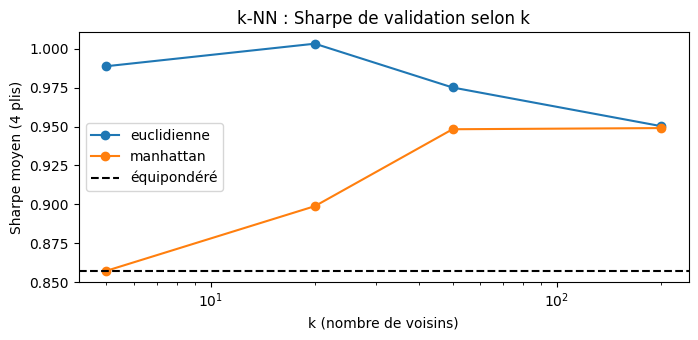

Réglage retenu : euclidienne, k = 20


In [13]:
CONFIGS["knn"] = {f"{nom}, k = {k}": dict(k=k, metric=metric)
                  for nom, metric in [("euclidienne", "euclidean"), ("manhattan", "cityblock")] for k in [5, 20, 50, 200]}
CV["knn"] = cross_validate("knn")

sharpe_val = CV["knn"].groupby("config", sort=False)["sharpe"].mean()      # Sharpe moyen des 4 plis
KNN_RETENU = sharpe_val.idxmax()                                           # réglage testé en partie 7

fig, ax = plt.subplots(figsize=(7, 3.5))
for nom, metric in [("euclidienne", "euclidean"), ("manhattan", "cityblock")]:
    configs = [c for c, cfg in CONFIGS["knn"].items() if cfg["metric"] == metric]
    ax.plot([CONFIGS["knn"][c]["k"] for c in configs], sharpe_val[configs], marker="o", label=nom)
ax.axhline(REF_CV.loc["Équipondéré", "sharpe"], color="k", ls="--", label="équipondéré")
ax.set_xscale("log"); ax.set_xlabel("k (nombre de voisins)"); ax.set_ylabel("Sharpe moyen (4 plis)")
ax.set_title("k-NN : Sharpe de validation selon k"); ax.legend(); plt.tight_layout(); plt.show()
print("Réglage retenu :", KNN_RETENU)

Les deux distances ne réagissent pas de la même façon au nombre de voisins. Avec la distance euclidienne, le Sharpe culmine autour de 20 voisins puis baisse légèrement quand $k$ augmente. Avec Manhattan, c'est l'inverse : peu de voisins donne le résultat le plus faible, au niveau de l'équipondéré, et le Sharpe monte avec $k$. Avec beaucoup de voisins, les deux courbes se rejoignent : l'allocation devient une moyenne sur un grand nombre de dates et dépend de moins en moins de la distance choisie. Presque tous les réglages font au moins aussi bien que l'équipondéré, mais les écarts entre eux restent faibles par rapport à la variation d'une période à l'autre : le choix du réglage compte peu.

### 3.3 Le k-NN retenu face aux références

On regarde si le réglage retenu fait mieux que l'équipondéré en Sharpe, s'il imite l'oracle mieux que l'allocation moyenne du train, et à quel prix.

In [14]:
lignes = [KNN_RETENU, "Équipondéré", "Moyenne des cibles du train"]
colonnes = {"sharpe": "Sharpe", "ce": "Entropie croisée", "turnover_an": "Turnover / an", "n_eff": "Actifs effectifs"}
summary(CV["knn"]).loc[lignes, list(colonnes)].rename(columns=colonnes)

,Sharpe,Entropie croisée,Turnover / an,Actifs effectifs
"euclidienne, k = 20",1.003,7.967,4.602,5.058
Équipondéré,0.857,2.726,0.242,15.000
Moyenne des cibles du train,0.898,2.721,0.245,13.446


Le k-NN fait un peu mieux que l'équipondéré, mais l'écart est petit par rapport à la variation d'une période à l'autre : seul le test dira s'il tient. Il imite mal l'oracle, car il met 0 % sur des actifs que l'oracle détient. Son portefeuille est aussi concentré et renouvelé plusieurs fois par an, donc plus risqué et plus coûteux en frais.

### 3.4 Ablation : les 10 variables globales seules

Sur les 160 variables, 150 décrivent les actions une à une et pèsent donc le plus dans la distance. Seules 10 décrivent le marché dans son ensemble (structure des corrélations, CAC, VIX, taux, crédit, Euribor). On refait la même validation croisée en ne gardant que ces 10 variables.

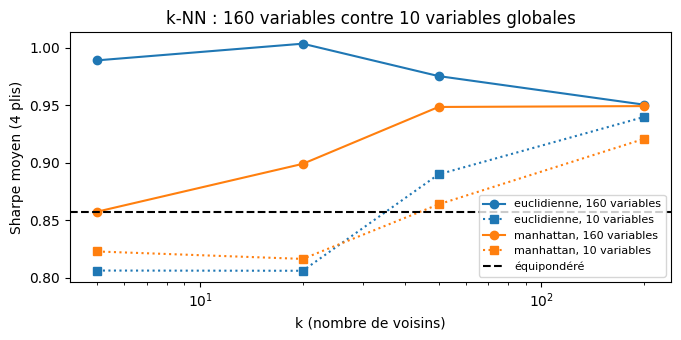

,Sharpe,Entropie croisée,Turnover / an,Actifs effectifs,Sharpe : écart-type entre plis
"160 variables (euclidienne, k = 20)",1.003,7.967,4.602,5.058,0.424
"10 variables (euclidienne, k = 200)",0.940,3.190,2.121,8.458,0.423
Équipondéré,0.857,2.726,0.242,15.000,
Moyenne des cibles du train,0.898,2.721,0.245,13.446,


In [15]:
# Les 10 variables globales, repérées par leur nom dans X.csv (même construction qu'en partie 4)
GLOBALES = [c for c in X.columns if c.endswith("__global") or c.startswith(("market__", "macro__"))]
RAW["tab_10"], STAT_AXES["tab_10"] = X[GLOBALES].to_numpy(), 0       # normalisée colonne par colonne, comme "tab"

# Même grille que plus haut, seule l'entrée change ; résultats rangés à part (le k-NN de la partie 7 ne change pas)
CONFIGS["knn_10"] = {nom: dict(cfg, inputs="tab_10") for nom, cfg in CONFIGS["knn"].items()}
CV["knn_10"] = cross_validate("knn_10")
sharpe_val_10 = CV["knn_10"].groupby("config", sort=False)["sharpe"].mean()
KNN_10_RETENU = sharpe_val_10.idxmax()

fig, ax = plt.subplots(figsize=(7, 3.5))
for (nom, metric), couleur in zip([("euclidienne", "euclidean"), ("manhattan", "cityblock")], ["C0", "C1"]):
    configs = [c for c, cfg in CONFIGS["knn"].items() if cfg["metric"] == metric]
    ks = [CONFIGS["knn"][c]["k"] for c in configs]
    ax.plot(ks, sharpe_val[configs], marker="o", color=couleur, label=f"{nom}, 160 variables")
    ax.plot(ks, sharpe_val_10[configs], marker="s", ls=":", color=couleur, label=f"{nom}, 10 variables")
ax.axhline(REF_CV.loc["Équipondéré", "sharpe"], color="k", ls="--", label="équipondéré")
ax.set_xscale("log"); ax.set_xlabel("k (nombre de voisins)"); ax.set_ylabel("Sharpe moyen (4 plis)")
ax.set_title("k-NN : 160 variables contre 10 variables globales"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

# Le meilleur réglage de chaque version, face aux références
def meilleur(famille, config, etiquette):
    ligne = summary(CV[famille]).loc[[config], list(colonnes)]
    ligne["sharpe_std"] = CV[famille].loc[CV[famille]["config"] == config, "sharpe"].std()   # écart entre les 4 plis
    return ligne.rename(index={config: f"{etiquette} ({config})"})

ablation = pd.concat([meilleur("knn", KNN_RETENU, "160 variables"),
                      meilleur("knn_10", KNN_10_RETENU, "10 variables"),
                      summary(CV["knn"]).loc[["Équipondéré", "Moyenne des cibles du train"], list(colonnes)]])
ablation.rename(columns={**colonnes, "sharpe_std": "Sharpe : écart-type entre plis"}).round(3).fillna("")

Le k-NN ne gagne rien à cette ablation : son Sharpe est un peu plus bas, mais dans la variation normale entre périodes. Avec 10 variables, le meilleur réglage prend beaucoup de voisins et se rapproche d'un portefeuille moyen, d'où une entropie croisée plus basse sans meilleure prédiction. Ces variables disent *quand* le marché ressemble au passé, pas *quelle* action acheter. On garde donc les 160 variables.

### 3.5 Un exemple : d'où viennent les voisins ?

On prend la date la plus récente du test, le 30/09/2025. On regarde d'où viennent ses voisins, puis on compare l'allocation du k-NN à celle de l'oracle.

In [16]:
def voisins_knn(date, config=KNN_RETENU):
    """Voisins d'une date du test (pris dans le train final 2006–2019), allocation k-NN et allocation oracle."""
    cfg, tr, t = CONFIGS["knn"][config], FINAL[0], X.index.get_loc(date)
    Z = prepare(["tab"], tr)[0]                                     # même normalisation que fit_predict
    voisins = tr[np.argsort(cdist(Z[[t]], Z[tr], cfg["metric"])[0])[:cfg["k"]]]
    mois = pd.Series(X.index[voisins].strftime("%Y-%m")).value_counts().sort_index()
    print(f"Dates des {cfg['k']} voisins : " + ", ".join(f"{m} ({n})" for m, n in mois.items()))
    poids = pd.DataFrame({"k-NN": Yn[voisins].mean(0), "Oracle": Yn[t]}, index=ASSETS) * 100
    return poids[(poids > 3).any(axis=1)].T.round(1)                # actifs à plus de 3 % chez l'un ou l'autre

voisins_knn("2025-09-30")

Dates des 20 voisins : 2007-11 (1), 2007-12 (2), 2017-07 (2), 2017-08 (8), 2017-12 (2), 2019-05 (5)


,MC.PA,BN.PA,TTE.PA,VIE.PA,GLE.PA,AIR.PA,AI.PA,CAP.PA,CASH
k-NN,8.7,11.2,12.6,17.6,2.3,10.2,19.6,7.1,10.0
Oracle,22.3,14.7,17.6,0.0,32.5,0.0,0.0,9.9,0.0


Les voisins viennent de quelques mois seulement, souvent consécutifs, donc de très peu d'épisodes de marché différents. Le k-NN répartit son portefeuille sur des actions que l'oracle ne détient pas, et passe presque à côté de celle sur laquelle l'oracle se concentre.

### 3.6 Conclusion

Les variables contiennent un peu d'information : à situation semblable, l'allocation passée aide légèrement, puisque le k-NN fait un peu mieux que l'équipondéré en validation, frais de transaction compris. Mais cet avantage reste petit par rapport à la variation d'une période à l'autre, et il se paie cher : l'allocation est concentrée sur quelques actifs, renouvelée plusieurs fois par an et éloignée de celle de l'oracle.

La raison tient à la méthode elle-même. Recopier le passé ne fonctionne que si le présent ressemble vraiment à une période du train. Or les voisins viennent de peu d'épisodes de marché, et leurs allocations oracle, concentrées, sont transmises telles quelles. Réduire les variables à celles qui décrivent le marché n'y change rien : le k-NN ne se diversifie qu'en prenant beaucoup de voisins, ce qui revient à se rapprocher de l'allocation moyenne du train.

Le k-NN fixe ainsi ce qu'on attend des réseaux des parties 4 à 6. Au lieu de recopier, ils apprennent une fonction qui relie les variables à l'allocation. Ils doivent imiter l'oracle mieux que l'allocation moyenne du train, et produire un portefeuille au moins aussi performant que l'équipondéré, sans la concentration ni les coûts du k-NN. Le verdict se fait sur le test, en partie 7, où tous les modèles sont jugés de la même manière.

## 4. Réseau dense (MLP)

**Principe.** Le réseau lit des variables de marché à la date $t$ et sort directement 16 poids :
`variables → n1 (ReLU, dropout) → n2 (ReLU, dropout) → 16 → softmax`. Le softmax garantit un portefeuille valide (poids positifs, somme 1, CASH compris).

**Démarche : 3 étapes, du plus général au plus précis.** Avec une cinquantaine de trimestres indépendants, le risque principal est le surapprentissage : on reste sur de **petits réseaux**, et chaque choix passe par la même validation croisée que les autres modèles (les 4 périodes de la partie 2).

| Étape | Question | Sur quel réseau | Note qui décide |
|---|---|---|---|
| 4.1 Perte | que doit apprendre le réseau ? (duel de la partie 2) | réseau de départ : 64-32, dropout 0,2, 160 variables | entropie croisée **et** Sharpe |
| 4.2 Variables | que doit-il lire ? (160, 85 ou 10 variables) | réseau de départ | entropie croisée |
| 4.3 Taille | comment le construire ? (taille × dropout) | avec les variables choisies → **MLP final** | entropie croisée |

*Les notes de validation sont un peu optimistes, car l'arrêt anticipé se fait sur la période notée (c'est le cas pour tous les modèles) ; le test final, lui, n'est utilisé qu'une fois.*

**Le réseau.** Une fonction fabrique le MLP avec `nn.Sequential` : les couches s'enchaînent dans l'ordre écrit. Chaque couche cachée = `Linear` (somme pondérée des entrées, ce sont les paramètres appris) + `ReLU` (non-linéarité) + `Dropout` (éteint au hasard une part des neurones pendant l'entraînement, contre le surapprentissage).

In [17]:
def creer_mlp(n1, n2, dropout, n_in=160):
    """MLP : n_in variables → n1 → n2 → 16 poids de portefeuille."""
    return nn.Sequential(
        nn.Linear(n_in, n1), nn.ReLU(), nn.Dropout(dropout),     # couche cachée 1
        nn.Linear(n1, n2), nn.ReLU(), nn.Dropout(dropout),       # couche cachée 2
        nn.Linear(n2, 16),                                       # 16 scores, un par actif
        nn.Softmax(dim=1))                                       # 16 poids >= 0 qui somment à 1

def n_params(model):
    """Nombre de paramètres appris (poids et biais de toutes les couches). Sert aussi aux parties 5 et 6."""
    total = 0
    for p in model.parameters():
        total = total + p.numel()
    return total

print("Paramètres : 64-32 →", n_params(creer_mlp(64, 32, 0.2)), "| 32-16 →", n_params(creer_mlp(32, 16, 0.2)),
      "| trimestres indépendants avant 2020 ≈", (X.index < "2020").sum() // N)

Paramètres : 64-32 → 12912 | 32-16 → 5952 | trimestres indépendants avant 2020 ≈ 57


**Une fiche de réglages par configuration.** `train` et `cross_validate` (partie 2) lisent une fiche : quel réseau fabriquer, avec quels paramètres, quelles entrées, quelle perte et quels réglages d'entraînement. Pour le MLP : taux d'apprentissage `lr = 1e-4`, 10 fois plus petit que pour les autres réseaux (vérifié à la fin de 4.3), lots de 64 dates, arrêt anticipé après 20 époques sans progrès (200 au maximum), pas de pénalité sur les poids (`wd = 0`) : la régularisation vient du dropout et de l'arrêt anticipé.

In [18]:
def fiche_mlp(n1, n2, dropout, perte="ce", lr=1e-4, lot=64, entrees="tab", n_in=160):
    """Fiche de réglages d'un MLP, au format attendu par train() et cross_validate()."""
    return {"model": creer_mlp,                                              # fonction qui fabrique le réseau
            "params": {"n1": n1, "n2": n2, "dropout": dropout, "n_in": n_in},
            "inputs": [entrees],                                             # features lues par le réseau
            "loss": perte,                                                   # "ce" (entropie croisée), "mse" ou "sharpe"
            "lr": lr, "wd": 0, "batch": lot,                                 # taille des pas d'Adam, pénalité, dates par lot
            "max_epochs": 200, "patience": 20}                               # arrêt anticipé

### 4.1 La perte : entropie croisée, MSE ou Sharpe ?

On décide d'abord ce que le réseau doit apprendre. Le réseau de départ est entraîné trois fois, avec chacune des trois pertes (entropie croisée, MSE, Sharpe), tout le reste identique. Pour la perte Sharpe, les lots sont plus grands (256 dates au lieu de 64), car un Sharpe calculé sur peu de dates varie beaucoup d'un lot à l'autre. Les pertes n'ont pas la même unité : on ne les compare pas entre elles, on compare les poids prédits par les trois réseaux, notés par le même juge (entropie croisée avec l'oracle et Sharpe). On garde l'entropie croisée sauf si une autre perte fait clairement mieux.

**Pourquoi ce réseau de départ ?** C'est celui qu'on construirait sans rien tester, fixé avant toute expérience : 2 couches cachées (le minimum pour une relation non linéaire), un entonnoir 64 → 32 vers les 16 sorties, un dropout standard de 0,2 et toutes les variables.

In [19]:
N1_DEPART, N2_DEPART, DROPOUT_DEPART = 64, 32, 0.2              # le réseau de départ

CONFIGS["mlp_pertes"] = {
    "entropie croisée": fiche_mlp(N1_DEPART, N2_DEPART, DROPOUT_DEPART, perte="ce"),
    "MSE": fiche_mlp(N1_DEPART, N2_DEPART, DROPOUT_DEPART, perte="mse"),
    "Sharpe, lots de 256": fiche_mlp(N1_DEPART, N2_DEPART, DROPOUT_DEPART, perte="sharpe", lot=256),
}
CV["mlp_pertes"] = cross_validate("mlp_pertes")

pertes = summary(CV["mlp_pertes"])
pertes["écart CE"] = pertes["ce"] - pertes.loc["entropie croisée", "ce"]          # > 0 : imite moins bien l'oracle
pertes["écart Sharpe"] = pertes["sharpe"] - pertes.loc["entropie croisée", "sharpe"]  # < 0 : moins bon Sharpe
pertes.round(3)

,ce,ce_std,sharpe,turnover_an,n_eff,époques,écart CE,écart Sharpe
entropie croisée,2.715,0.065,0.901,0.672,14.758,7.0,0.000,0.000
MSE,2.713,0.086,0.903,0.610,14.619,3.5,-0.002,0.002
"Sharpe, lots de 256",2.915,0.298,0.899,1.003,13.103,4.5,0.200,-0.002
Équipondéré,2.726,NaN,0.857,0.242,15.000,NaN,0.011,-0.044
Moyenne des cibles du train,2.721,NaN,0.898,0.245,13.446,NaN,0.006,-0.003


La MSE fait jeu égal avec l'entropie croisée : même imitation de l'oracle (2,713 contre 2,715) et même Sharpe de validation (0,903 contre 0,901). La perte Sharpe ne donne pas un meilleur Sharpe (0,899) et imite beaucoup moins bien l'oracle (2,915, avec une forte dispersion entre périodes). Aucune ne fait mieux : on garde l'entropie croisée, qui est aussi la perte des autres réseaux.

### 4.2 Les variables : 160, 85 ou 10 ?

Le dataset contient 160 variables : 150 décrivent chaque action (momentum, volatilité, drawdown, corrélation au CAC) et 10 décrivent le marché dans son ensemble (3 valeurs propres de la corrélation entre actions, tendance et volatilité du CAC, VIX et sa variation, pente des taux, spread de crédit, Euribor). Avec ~57 trimestres, les 150 variables par action risquent surtout d'apporter du bruit. On compare donc le réseau de départ, entraîné avec l'entropie croisée, avec **trois groupes de variables définis à l'avance** : les 160, le momentum des actions avec les 10 globales (85), et les 10 globales seules.

Les variables ne sont pas recalculées : on garde seulement certaines colonnes de `X.csv`, repérées par leur nom. Les 16 poids en sortie ne changent pas.

In [20]:
colonnes_momentum = []                                       # mom_5 ... mom_252 des 15 actions
colonnes_globales = []                                       # valeurs propres, marché, macro
for c in X.columns:
    if c.startswith("mom_"):
        colonnes_momentum.append(c)
    elif c.endswith("__global") or c.startswith("market__") or c.startswith("macro__"):
        colonnes_globales.append(c)

RAW["tab_85"] = X[colonnes_momentum + colonnes_globales].to_numpy()
RAW["tab_10"] = X[colonnes_globales].to_numpy()
STAT_AXES["tab_85"] = 0                                      # normalisation colonne par colonne, comme "tab"
STAT_AXES["tab_10"] = 0
print("Momentum :", len(colonnes_momentum), "colonnes | globales :", len(colonnes_globales), "colonnes")

Momentum : 75 colonnes | globales : 10 colonnes


In [21]:
# Les trois groupes de variables : nom → (entrée, nombre de variables)
ENTREES = {"160 variables (toutes)": ("tab", 160),
           "85 variables (momentum + globales)": ("tab_85", 85),
           "10 variables (globales seules)": ("tab_10", 10)}

CONFIGS["mlp_variables"] = {}
for nom in ENTREES:
    entrees, n_in = ENTREES[nom]
    CONFIGS["mlp_variables"][nom] = fiche_mlp(N1_DEPART, N2_DEPART, DROPOUT_DEPART, entrees=entrees, n_in=n_in)

CV["mlp_variables"] = cross_validate("mlp_variables")
variables = summary(CV["mlp_variables"])
variables.round(3)

,ce,ce_std,sharpe,turnover_an,n_eff,époques
160 variables (toutes),2.715,0.065,0.901,0.672,14.758,7.0
85 variables (momentum + globales),2.716,0.067,0.905,0.822,14.117,17.0
10 variables (globales seules),2.716,0.091,0.898,0.603,13.910,13.0
Équipondéré,2.726,NaN,0.857,0.242,15.000,NaN
Moyenne des cibles du train,2.721,NaN,0.898,0.245,13.446,NaN


**Règle de choix**, la même pour les variables et pour la taille, fixée avant de regarder les résultats :
1. on repère la plus petite entropie croisée moyenne ;
2. celles qui en sont à moins d'un écart-type entre plis (`ce_std`) sont jugées **équivalentes** : leur écart ne se distingue pas du bruit d'une période à l'autre ;
3. parmi elles, on prend **le modèle le plus simple** (ici : le moins de variables).

Les 160 variables ont la meilleure note (2,715), mais les deux autres groupes sont à seulement 0,001 derrière, bien moins que la variation normale entre périodes (0,065). Les trois sont donc ex æquo. Dans ce cas, on prend le plus simple : les 10 variables.

### 4.3 La taille : grille taille × dropout

Avec les variables retenues en 4.2, toutes les combinaisons de 2 tailles (64-32, 32-16) et de 2 dropouts (0,2 et 0,4), entraînées avec l'entropie croisée. On applique **la même règle** : parmi les configurations équivalentes à la meilleure, on prend **le plus petit réseau** (moins de paramètres, donc moins de risque de surapprentissage) ; à taille égale, la plus petite entropie croisée. Le résultat est le **MLP final**, utilisé pour le backtest de la partie 7.

In [22]:
entrees, n_in = "tab_10", 10                               # les 10 variables globales, retenues en 4.2

GRILLE = [(64, 32, 0.2), (64, 32, 0.4), (32, 16, 0.2), (32, 16, 0.4)]    # (neurones couche 1, couche 2, dropout)

CONFIGS["mlp_grille"] = {}
REGLAGES = {}                                                # nom de la configuration → (n1, n2, dropout)
for n1, n2, dropout in GRILLE:
    nom = f"{n1}-{n2}, dropout {dropout}"
    CONFIGS["mlp_grille"][nom] = fiche_mlp(n1, n2, dropout, entrees=entrees, n_in=n_in)
    REGLAGES[nom] = (n1, n2, dropout)

CV["mlp_grille"] = cross_validate("mlp_grille")
summary(CV["mlp_grille"])

,ce,ce_std,sharpe,turnover_an,n_eff,époques
"64-32, dropout 0.2",2.716,0.091,0.898,0.603,13.910,13.0
"64-32, dropout 0.4",2.713,0.093,0.896,0.583,14.017,16.5
"32-16, dropout 0.2",2.684,0.052,0.933,0.503,14.017,17.0
"32-16, dropout 0.4",2.686,0.046,0.925,0.493,14.155,20.0
Équipondéré,2.726,NaN,0.857,0.242,15.000,NaN
Moyenne des cibles du train,2.721,NaN,0.898,0.245,13.446,NaN


Vu les résultats ci-dessus, on garde le réseau **32-16 avec dropout 0,2** : les 4 configurations sont ex æquo, et c'est le plus petit réseau avec la meilleure note (2,684). C'est le **MLP final** : il imite l'oracle mieux que la moyenne des cibles du train (2,684 contre 2,721) et que l'équipondéré, avec un Sharpe de validation de 0,933.

**Pourquoi lr = 1e-4 ?** Les autres réseaux utilisent le pas habituel d'Adam (1e-3). On réentraîne le MLP final avec ce pas 10 fois plus grand, tout le reste identique, et on regarde la colonne « époques » : l'époque où le réseau atteint son meilleur score.

In [23]:
MLP_RETENU = "32-16, dropout 0.2"                             # le MLP final, choisi ci-dessus
MLP_FINAL = ("mlp_grille", MLP_RETENU)                        # utilisé pour le backtest (partie 7)

n1, n2, dropout = REGLAGES[MLP_RETENU]                        # le MLP final

# Le MLP final avec un pas 10 fois plus grand (1e-3), tout le reste identique
CONFIGS["mlp_lr"] = {"lr = 1e-3": fiche_mlp(n1, n2, dropout, lr=1e-3, entrees=entrees, n_in=n_in)}
CV["mlp_lr"] = cross_validate("mlp_lr")

# Comparaison avec le MLP final (lr = 1e-4)
final = summary(CV["mlp_grille"]).loc[[MLP_RETENU]]
final.index = ["MLP final (lr = 1e-4)"]
pd.concat([final, summary(CV["mlp_lr"])]).round(3)

,ce,ce_std,sharpe,turnover_an,n_eff,époques
MLP final (lr = 1e-4),2.684,0.052,0.933,0.503,14.017,17.0
lr = 1e-3,2.687,0.046,0.928,0.494,14.008,2.0
Équipondéré,2.726,NaN,0.857,0.242,15.000,NaN
Moyenne des cibles du train,2.721,NaN,0.898,0.245,13.446,NaN


La note est la même, mais avec 1e-3 le réseau atteint son meilleur score dès la 2ᵉ époque, puis commence à surapprendre, contre 17 époques avec 1e-4 : avec un pas plus petit, l'apprentissage est progressif et plus stable. On garde 1e-4.

## 5. U-Net 1D

**Principe.** Le U-Net lit les **60 derniers rendements journaliers des 15 actions** comme un signal à 15 canaux. Un **encodeur** convolutif réduit la résolution temporelle (60 → 30 → 15 jours) pour capter les mouvements lents ; un **décodeur** la restaure, et des **connexions directes** (*skip connections*) lui redonnent le détail journalier perdu en chemin. La moyenne temporelle de la sortie passe dans une couche linéaire puis un softmax.

**Démarche de choix**, la même que pour le MLP :
1. **la perte** (5.1) : le U-Net de référence, fixé avant toute expérience (c = 8 filtres, 1 niveau, noyau 3, dropout 0,1), est entraîné avec chacune des trois pertes, tout le reste identique ;
2. **les réglages** (5.2) : avec la perte retenue, on fait varier un réglage à la fois autour de la référence (largeur, profondeur, noyau, dropout), en validation croisée.

In [24]:
class UNet(nn.Module):
    """U-Net 1D : c filtres au 1er niveau (doublés à chaque niveau), `depth` niveaux de sous-échantillonnage, noyaux de taille k."""
    def __init__(self, c=8, depth=2, k=3, dropout=0.1):
        super().__init__()
        block = lambda i, o: nn.Sequential(nn.Conv1d(i, o, k, padding=k // 2), nn.ReLU(), nn.Conv1d(o, o, k, padding=k // 2), nn.ReLU())
        ch = [c * 2 ** l for l in range(depth + 1)]                                  # c, 2c, 4c...
        self.enc = nn.ModuleList([block(15 if l == 0 else ch[l - 1], ch[l]) for l in range(depth)])
        self.mid = block(ch[depth - 1], ch[depth])
        self.pool = nn.MaxPool1d(2)
        self.up = nn.ModuleList([nn.ConvTranspose1d(ch[l + 1], ch[l], 2, stride=2) for l in reversed(range(depth))])
        self.dec = nn.ModuleList([block(2 * ch[l], ch[l]) for l in reversed(range(depth))])
        self.drop, self.head = nn.Dropout(dropout), nn.Linear(c, 16)

    def forward(self, x):                                       # x : (B, 60 jours, 15 actions)
        h, skips = x.transpose(1, 2), []
        for enc in self.enc:                                    # descente : 60 → 30 (→ 15) jours
            h = enc(h); skips.append(h); h = self.pool(h)
        h = self.mid(h)
        for up, dec, s in zip(self.up, self.dec, reversed(skips)):   # remontée + connexions directes
            h = dec(torch.cat([up(h), s], dim=1))
        return torch.softmax(self.head(self.drop(h.mean(2))), dim=-1)

def fiche_unet(c, depth, k, dropout, perte="ce", lot=128, lr=1e-3, wd=1e-4):
    """Fiche de réglages d'un U-Net, au format attendu par train() et cross_validate()."""
    return dict(model=UNet, params=dict(c=c, depth=depth, k=k, dropout=dropout), inputs=["seq_j"],
                loss=perte, batch=lot, lr=lr, wd=wd)

UNET_REF = (8, 1, 3, 0.1)                                         # (c, profondeur, noyau, dropout) : le U-Net de référence


### 5.1 La perte : entropie croisée, MSE ou Sharpe ?

Même duel que pour le MLP (4.1) : le U-Net de référence est entraîné avec chacune des trois pertes, mêmes plis, même arrêt anticipé ; lots de 256 dates pour la perte Sharpe. Les trois réseaux sont notés par le même juge (entropie croisée avec l'oracle et Sharpe de validation). On garde l'entropie croisée sauf si une autre perte fait nettement et régulièrement mieux.

In [25]:
CONFIGS["unet_pertes"] = {
    "entropie croisée": fiche_unet(*UNET_REF, perte="ce"),
    "MSE": fiche_unet(*UNET_REF, perte="mse"),
    "Sharpe, lots de 256": fiche_unet(*UNET_REF, perte="sharpe", lot=256),
}
CV["unet_pertes"] = cross_validate("unet_pertes")

pertes_unet = summary(CV["unet_pertes"])
pertes_unet["écart CE"] = pertes_unet["ce"] - pertes_unet.loc["entropie croisée", "ce"]              # > 0 : imite moins bien l'oracle
pertes_unet["écart Sharpe"] = pertes_unet["sharpe"] - pertes_unet.loc["entropie croisée", "sharpe"]  # < 0 : moins bon Sharpe
pertes_unet.round(3)

,ce,ce_std,sharpe,turnover_an,n_eff,époques,écart CE,écart Sharpe
entropie croisée,2.679,0.071,0.954,1.064,13.165,13.0,0.000,0.000
MSE,2.719,0.077,0.904,0.244,14.599,19.5,0.040,-0.050
"Sharpe, lots de 256",3.005,0.418,0.913,0.443,12.942,1.0,0.326,-0.041
Équipondéré,2.726,NaN,0.857,0.242,15.000,NaN,0.047,-0.097
Moyenne des cibles du train,2.721,NaN,0.898,0.245,13.446,NaN,0.042,-0.056


**Lecture.** L'entropie croisée l'emporte sur les deux critères :
- **imitation de l'oracle** : 2,679 contre 2,719 pour la MSE et 3,005 pour la perte Sharpe. La MSE reste au niveau de la moyenne des cibles du train (2,721) : elle n'extrait presque rien des 60 derniers jours ;
- **Sharpe de validation** : 0,954 contre 0,904 (MSE) et 0,913 (Sharpe). Sur les 4 périodes, l'entropie croisée a le meilleur Sharpe 3 fois face à la MSE et 4 fois face à la perte Sharpe.

La perte Sharpe confirme ce qu'on a vu avec le MLP : elle s'arrête dès la 1ʳᵉ époque sur 3 périodes sur 4 et donne une imitation très instable (écart-type 0,42 entre périodes). On garde donc l'**entropie croisée** pour la grille de 5.2.

### 5.2 Les réglages, avec la perte retenue

Six configurations autour de la référence, en ne changeant qu'un réglage à la fois, toutes entraînées avec la perte retenue en 5.1. On retient la plus petite entropie croisée moyenne.

In [26]:
PERTE_UNET = "ce"                                                # la perte retenue en 5.1 : "ce", "mse" ou "sharpe"
LOT_UNET = 256 if PERTE_UNET == "sharpe" else 128                 # lots plus grands pour la perte Sharpe, comme en 5.1

GRILLE_UNET = [UNET_REF,                                          # (c, profondeur, noyau, dropout) : la référence
               (4, 1, 3, 0.1), (16, 1, 3, 0.1),                    # largeur
               (8, 2, 3, 0.1),                                     # profondeur
               (8, 1, 5, 0.1),                                     # noyau
               (8, 1, 3, 0.3)]                                     # dropout

CONFIGS["unet"] = {}
for c, depth, k, dropout in GRILLE_UNET:
    nom = f"c={c}, prof={depth}, noyau={k}, dropout={dropout}"
    if PERTE_UNET != "ce":                                        # le nom indique la perte : pas de mélange avec les résultats déjà enregistrés
        nom += f", perte {PERTE_UNET}"
    CONFIGS["unet"][nom] = fiche_unet(c, depth, k, dropout, perte=PERTE_UNET, lot=LOT_UNET)

print("Paramètres :", {nom: n_params(UNet(**cfg["params"])) for nom, cfg in CONFIGS["unet"].items()})
CV["unet"] = cross_validate("unet")
res_unet = summary(CV["unet"])
UNET_RETENU = res_unet.loc[list(CONFIGS["unet"]), "ce"].idxmin()
print("U-Net retenu :", UNET_RETENU)
res_unet

Paramètres : {'c=8, prof=1, noyau=3, dropout=0.1': 2752, 'c=4, prof=1, noyau=3, dropout=0.1': 840, 'c=16, prof=1, noyau=3, dropout=0.1': 9840, 'c=8, prof=2, noyau=3, dropout=0.1': 10800, 'c=8, prof=1, noyau=5, dropout=0.1': 4272, 'c=8, prof=1, noyau=3, dropout=0.3': 2752}
U-Net retenu : c=8, prof=1, noyau=3, dropout=0.1


,ce,ce_std,sharpe,turnover_an,n_eff,époques
"c=8, prof=1, noyau=3, dropout=0.1",2.679,0.071,0.954,1.064,13.165,13.0
"c=4, prof=1, noyau=3, dropout=0.1",2.725,0.063,0.910,0.314,15.024,8.0
"c=16, prof=1, noyau=3, dropout=0.1",2.701,0.039,0.935,0.565,13.997,3.5
"c=8, prof=2, noyau=3, dropout=0.1",2.688,0.072,0.922,0.524,13.619,7.5
"c=8, prof=1, noyau=5, dropout=0.1",2.701,0.077,0.926,0.453,14.427,7.5
"c=8, prof=1, noyau=3, dropout=0.3",2.702,0.036,0.911,0.890,13.771,13.0
Équipondéré,2.726,NaN,0.857,0.242,15.000,NaN
Moyenne des cibles du train,2.721,NaN,0.898,0.245,13.446,NaN


**Lecture.** Six configurations autour de la référence (c = 8, 1 niveau, noyau 3, dropout 0,1), en ne changeant qu'un réglage à la fois. L'entropie croisée se compare à la ligne « moyenne des cibles du train » : c'est le seuil en dessous duquel le réseau a extrait de l'information des 60 derniers jours.

| Variante | Entropie croisée | Sharpe (validation) |
|---|---|---|
| Référence (c = 8) | **2,679** ± 0,071 | 0,95 |
| Largeur c = 4 / c = 16 | 2,725 / 2,701 | 0,91 / 0,94 |
| Profondeur 2 | 2,688 | 0,92 |
| Noyau 5 | 2,701 | 0,93 |
| Dropout 0,3 | 2,702 | 0,91 |

Tous les écarts (≤ 0,046) sont inférieurs à la variation entre périodes (écart-type 0,04 à 0,08) : la taille du U-Net compte peu. On retient la configuration de référence, qui a la meilleure entropie croisée et le meilleur Sharpe de validation.

## 6. Réseaux récurrents et attention : l'ordre des observations aide-t-il ?

Ici le réseau lit une **séquence** de rendements et la résume en un vecteur, d'où sortent les poids. Trois architectures, de la plus naïve à la plus structurée :

| | **V0 : LSTM global** | **V1 : LSTM partagé** | **V1T : Transformer partagé** |
|---|---|---|---|
| Ce que lit l'encodeur | 1 séquence : 60 jours × 15 actions | 15 séquences : 52 semaines × (action, CAC) | idem V1 |
| Encodeur | un LSTM pour tout le marché | **le même LSTM** appliqué à chaque action | une couche d'**auto-attention** appliquée à chaque action |
| Résumé de la séquence | dernier état caché | dernier état caché | **moyenne** sur les 52 semaines |
| Sortie | 16 scores → softmax | 1 score par action + 1 score CASH → softmax | idem V1 |

**Pourquoi partager l'encodeur ?** Dans V0, le réseau doit apprendre séparément le comportement de chaque action à partir de ~50 trimestres. Dans V1 et V1T, un seul petit encodeur apprend « comment noter une trajectoire », et il voit 15 fois plus d'exemples. Le softmax final met ensuite les 15 scores en concurrence.

**Ce que change le Transformer.** Le LSTM lit l'année semaine après semaine et garde tout dans une petite mémoire, qui privilégie les dernières semaines. Le Transformer regarde toutes les semaines d'un coup : chaque semaine est comparée aux autres (l'attention), puis l'année est résumée par une moyenne où chaque semaine compte.

**Démarche de choix.** Le tableau ci-dessous compare les architectures ; une **grille minimale** est ensuite rejouée juste après : taille de l'état (8, 16 ou 32) et nombre de couches (1 ou 2) pour les deux LSTM, dimension d (8 ou 16) et dropout (0 ou 0,1) pour le Transformer. Dans cette section, on retient la configuration dont l'entropie croisée **moyenne + écart-type entre périodes** est la plus basse : une bonne moyenne tirée par une seule période n'est pas fiable. Les autres réglages sont fixés a priori : LSTM plutôt que GRU et pas de dropout pour les LSTM (explorés lors de nos travaux préparatoires, sans gain), 2 têtes et une couche dense de 32 pour le Transformer (valeurs standard). Une variante n'a rien apporté et n'est pas reprise : une attention entre les actions. L'apport des features et de l'ordre des semaines est mesuré plus bas, dans l'étude d'ablation.

In [27]:
class V0(nn.Module):                                      # un LSTM lit les 15 actions ensemble
    def __init__(self, hidden=16, layers=2):
        super().__init__()
        self.rec, self.head = nn.LSTM(15, hidden, num_layers=layers, batch_first=True), nn.Linear(hidden, 16)
    def forward(self, x):                                       # x : (B, 60, 15)
        return torch.softmax(self.head(self.rec(x)[0][:, -1]), dim=-1)

class V1(nn.Module):                                            # un LSTM partagé : le même encodeur pour chaque action
    def __init__(self, hidden=16, layers=2):
        super().__init__()
        self.rec = nn.LSTM(2, hidden, num_layers=layers, batch_first=True)
        self.score, self.cash = nn.Linear(hidden, 1), nn.Linear(hidden, 1)
    def encode(self, s):                                        # s : (n, 52, 2) → dernier état caché : (n, hidden)
        return self.rec(s)[0][:, -1]
    def forward(self, x):                                       # x : (B, 15, 52, 2)
        B, n, T, C = x.shape
        h = self.encode(x.reshape(B * n, T, C)).reshape(B, n, -1)                       # un résumé par action : (B, 15, hidden)
        scores = torch.cat([self.score(h).squeeze(-1), self.cash(h.mean(1))], dim=-1)   # 15 actions + CASH
        return torch.softmax(scores, dim=-1)

class V1T(nn.Module):                                    # un Transformer partagé : le même encodeur pour chaque action
    def __init__(self, d=16, heads=2, ff=32, dropout=0.1, channels=2, order=True):
        super().__init__()
        self.order = order                               # False : ablation, sans encodage de position
        self.inp = nn.Linear(channels, d)                      # chaque semaine (action, CAC) : vecteur de taille d, mêmes poids pour toutes
        self.pos = nn.Parameter(0.02 * torch.randn(1, 52, d))   # position de la semaine apprise
        # une couche d'encodeur : auto-attention à `heads` têtes (chaque semaine regarde les 52 semaines),
        # puis réseau dense d → ff → d appliqué à chaque semaine, connexions résiduelles et normalisation
        layer = nn.TransformerEncoderLayer(d, heads, ff, dropout, batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, 1, enable_nested_tensor=False)
        self.score, self.cash = nn.Linear(d, 1), nn.Linear(d, 1)
    def encode(self, s):                                        # s : (n, 52, 2) → résumé de chaque action : (n, d)
        z = self.inp(s)
        if self.order:                                   # ajoute la position de chaque semaine
            z = z + self.pos
        return self.enc(z).mean(1)         # moyenne sur les 52 semaines (le LSTM garde son dernier état)
    def forward(self, x):                                       # x : (B, 15, 52, 2)
        B, n, T, C = x.shape
        h = self.encode(x.reshape(B * n, T, C)).reshape(B, n, -1)                       # un résumé par action : (B, 15, d)
        scores = torch.cat([self.score(h).squeeze(-1), self.cash(h.mean(1))], dim=-1)   # 15 actions + CASH (moyenne des résumés des actions)
        return torch.softmax(scores, dim=-1)


CONFIGS["rec"] = {"V0 : LSTM global": dict(model=V0, params=dict(hidden=16, layers=2), inputs=["seq_j"]),
                  "V1 : LSTM partagé": dict(model=V1, params=dict(hidden=16, layers=2), inputs=["seq_h"]),
                  "V1T : Transformer, d = 8": dict(model=V1T, params=dict(d=8), inputs=["seq_h"]),
                  "V1T : Transformer, d = 16": dict(model=V1T, params=dict(d=16), inputs=["seq_h"]),
                  "V1T : Transformer, d = 16, perte MSE": dict(model=V1T, params=dict(d=16), inputs=["seq_h"], loss="mse"),       # duel des pertes (partie 2)
                  "V1T : Transformer, d = 16, perte Sharpe": dict(model=V1T, params=dict(d=16), inputs=["seq_h"], loss="sharpe", batch=256)}
for nom, cfg in CONFIGS["rec"].items():
    print(f"{nom} : {n_params(cfg['model'](**cfg['params']))} paramètres")
CV["rec"] = cross_validate("rec")
summary(CV["rec"])

V0 : LSTM global : 4560 paramètres
V1 : LSTM partagé : 3490 paramètres
V1T : Transformer, d = 8 : 1330 paramètres
V1T : Transformer, d = 16 : 3138 paramètres
V1T : Transformer, d = 16, perte MSE : 3138 paramètres
V1T : Transformer, d = 16, perte Sharpe : 3138 paramètres


,ce,ce_std,sharpe,turnover_an,n_eff,époques
V0 : LSTM global,2.681,0.080,0.963,0.416,14.512,2.0
V1 : LSTM partagé,2.716,0.043,0.875,0.826,14.970,7.0
"V1T : Transformer, d = 8",2.716,0.035,0.854,0.515,15.177,11.0
"V1T : Transformer, d = 16",2.691,0.042,0.906,0.857,14.458,8.5
"V1T : Transformer, d = 16, perte MSE",2.745,0.009,0.855,0.255,15.802,1.5
"V1T : Transformer, d = 16, perte Sharpe",3.753,1.958,0.862,0.200,12.246,2.0
Équipondéré,2.726,NaN,0.857,0.242,15.000,NaN
Moyenne des cibles du train,2.721,NaN,0.898,0.245,13.446,NaN


- **V0 a la meilleure moyenne (2,681), mais c'est le modèle le plus instable** (écart-type 0,080) : son avance vient d'une seule période (2014-15 : 2,596), et il s'arrête dès la première époque sur deux périodes, donc sans vraiment exploiter la séquence.
- **Le Transformer partagé (V1T, d = 16)** a le meilleur compromis entre moyenne et stabilité (2,691 ± 0,042) : c'est la configuration retenue. Le LSTM partagé et le petit Transformer (d = 8) sont en retrait (2,716).
- Notre interprétation : l'oracle dépend surtout de statistiques calculées sur **toute** la fenêtre (volatilité, corrélation au marché). La moyenne sur les 52 semaines du Transformer les capte directement, alors que le dernier état d'un LSTM privilégie le passé récent. L'étude d'ablation ci-dessous le confirme.
- **Duel des pertes (partie 2).** Avec la MSE, le Transformer s'arrête après 1 à 3 époques et imite nettement moins bien l'oracle (2,745 contre 2,691, Sharpe 0,855 contre 0,906). Avec la perte Sharpe, le Sharpe est plus bas (0,862) et l'apprentissage est instable (entropie croisée de 6,69 sur 2018-19). On garde l'entropie croisée.

**Grille minimale de cross val pour justifier le choix des modeles fixés plus haut.** Les configurations du tableau précédent sont relues, seules les nouvelles sont entraînées. On affiche la meilleure configuration de chaque architecture selon la règle (moyenne + écart-type) ; la grille complète est enregistrée dans `cv_rec.csv`.

In [28]:
# Grille minimale : taille de l'état × nombre de couches pour les LSTM, dimension × dropout pour le Transformer
CONFIGS["rec_grille"] = {}
for hidden in [8, 16, 32]:
    for layers in [1, 2]:
        CONFIGS["rec_grille"][f"V0, état {hidden}, {layers} couche(s)"] = dict(model=V0, params=dict(hidden=hidden, layers=layers), inputs=["seq_j"])
        CONFIGS["rec_grille"][f"V1, état {hidden}, {layers} couche(s)"] = dict(model=V1, params=dict(hidden=hidden, layers=layers), inputs=["seq_h"])
for d in [8, 16]:
    for dropout in [0.0, 0.1]:
        CONFIGS["rec_grille"][f"V1T, d = {d}, dropout {dropout}"] = dict(model=V1T, params=dict(d=d, dropout=dropout), inputs=["seq_h"])

CV["rec_grille"] = cross_validate("rec_grille")
grille = summary(CV["rec_grille"])
grille["critère"] = grille["ce"] + grille["ce_std"]          # règle de choix : le plus bas
grille.sort_values("critère").head(6)                        # les 6 meilleures configurations

,ce,ce_std,sharpe,turnover_an,n_eff,époques,critère
"V1T, d = 16, dropout 0.1",2.691,0.042,0.906,0.857,14.458,8.5,2.733
"V1T, d = 16, dropout 0.0",2.680,0.055,0.909,0.939,14.313,9.5,2.735
"V1T, d = 8, dropout 0.0",2.709,0.038,0.874,0.724,14.690,7.0,2.747
"V0, état 8, 1 couche(s)",2.687,0.061,0.950,0.444,14.240,7.5,2.748
"V1T, d = 8, dropout 0.1",2.716,0.035,0.854,0.515,15.177,11.0,2.751
"V1, état 32, 2 couche(s)",2.737,0.015,0.879,0.801,15.218,5.5,2.752


### Étude d'ablation : l'ordre des semaines et les features comptent-ils ?

On part du Transformer retenu (V1T, d = 16) et on ne change **qu'une chose à la fois**, avec la même validation croisée :
- **sans encodage de position** : le modèle ne sait plus dans quel ordre sont les semaines. S'il fait aussi bien, c'est que seules des statistiques sur l'année comptent (volatilité, lien au marché), pas leur chronologie ;
- **sans le canal CAC** : une seule entrée par semaine, le rendement de l'action. Le modèle ne peut plus mesurer le lien de l'action au marché ;
- **V2T = V1T + features** : la tête de score reçoit aussi les 10 features de l'action (momentum, volatilités, drawdown, corrélation au CAC) et les 10 features globales ; le score du CASH vient des features globales ;
- **V2 = LSTM partagé + features** : la même tête, sur l'encodeur de V1, à comparer à V1.

Une seule graine et 4 plis : un écart plus petit que l'écart-type entre plis (`ce_std`) ne permet pas de conclure.

In [29]:
# Les 10 features de chaque action, rangées en tableau (dates, 15 actions, 10 features)
TYPES = ["mom_5", "mom_21", "mom_63", "mom_126", "mom_252", "vol_21", "vol_63", "dvol_63", "dd_252", "corrmkt_63"]
features_par_action = []
for f in TYPES:
    colonnes = [f"{f}__{t}" for t in TICKERS]              # la feature f pour les 15 actions
    features_par_action.append(X[colonnes].to_numpy())
RAW["tab_actions"] = np.stack(features_par_action, axis=-1)
STAT_AXES["tab_actions"] = (0, 1)        # normalisation : une moyenne et un écart-type par feature, toutes dates et actions confondues

# Les trajectoires hebdomadaires sans le canal CAC : on ne garde que le canal 0 (l'action)
RAW["seq_h1"] = RAW["seq_h"][:, :, :, :1]
STAT_AXES["seq_h1"] = (0, 1, 2)          # normalisation : une seule échelle pour le canal

class V2T(V1T):                                          # V1T + features dans la tête de score
    def __init__(self, d=16, heads=2, ff=32, dropout=0.1):
        super().__init__(d, heads, ff, dropout)
        self.score, self.cash = nn.Linear(d + 20, 1), nn.Linear(10, 1)   # résumé + 10 features de l'action + 10 globales
    def forward(self, x, fa, fg):                        # fa : (B, 15, 10), fg : (B, 10)
        B, n, T, C = x.shape
        h = self.encode(x.reshape(B * n, T, C)).reshape(B, n, -1)
        z = torch.cat([h, fa, fg.unsqueeze(1).expand(-1, n, -1)], dim=-1)
        scores = torch.cat([self.score(z).squeeze(-1), self.cash(fg)], dim=-1)   # CASH : à partir des features globales
        return torch.softmax(scores, dim=-1)

CONFIGS["ablation"] = {
    "V1T sans encodage de position": dict(model=V1T, params=dict(d=16, order=False), inputs=["seq_h"]),
    "V1T sans le canal CAC": dict(model=V1T, params=dict(d=16, channels=1), inputs=["seq_h1"]),
    "V2T : V1T + features": dict(model=V2T, params=dict(d=16), inputs=["seq_h", "tab_actions", "tab_10"])}
CV["ablation"] = cross_validate("ablation")

reference = CV["rec"][CV["rec"]["config"].isin(["V1T : Transformer, d = 16"])]
summary(pd.concat([reference, CV["ablation"]]))

,ce,ce_std,sharpe,turnover_an,n_eff,époques
"V1T : Transformer, d = 16",2.691,0.042,0.906,0.857,14.458,8.5
V1T sans encodage de position,2.676,0.054,0.914,0.823,14.051,12.0
V1T sans le canal CAC,2.713,0.031,0.870,0.626,15.143,7.0
V2T : V1T + features,2.687,0.050,0.924,1.132,13.716,7.0
Équipondéré,2.726,NaN,0.857,0.242,15.000,NaN
Moyenne des cibles du train,2.721,NaN,0.898,0.245,13.446,NaN


**Lecture.** Chaque variante se compare au Transformer retenu (V1T, 2,691 ± 0,042) période par période : seul un écart de même sens sur la plupart des périodes est interprétable.

| Variante | Entropie croisée | Face à V1T, période par période | Conclusion |
|---|---|---|---|
| Sans encodage de position | 2,676 ± 0,054 | mieux sur 3 périodes, égal sur la 4ᵉ | l'ordre des semaines n'apporte rien |
| Sans le canal CAC | 2,713 ± 0,031 | moins bien sur 3 périodes (jusqu'à +0,05 en 2018-19) | le lien au marché aide, modérément |
| V2T : V1T + features | 2,687 ± 0,050 | écarts minimes dans les deux sens | les features n'apportent rien |
| V2 : LSTM + features | 2,732 ± 0,030 | face à V1 (2,716) : un peu moins bien | même constat côté LSTM |

- **L'ordre des semaines ne sert pas.** Sans encodage de position, le Transformer ne sait plus quand chaque semaine a eu lieu, et il fait au moins aussi bien. Le gain des modèles séquentiels ne vient donc pas de la chronologie, mais de deux choix d'architecture : **partager l'encodeur** entre les actions et **résumer toute l'année** (la moyenne sur les 52 semaines). Le modèle se comporte comme un calcul de statistiques sur l'année.
- **Le canal CAC est utile.** Sans lui, le modèle ne voit que la trajectoire de l'action et ne peut plus mesurer son lien au marché. L'écart moyen (+0,022) ne vaut que la moitié de l'écart-type entre périodes, mais il va dans le même sens sur 3 périodes sur 4.
- **Les features n'ajoutent rien à la trajectoire**, ni pour le Transformer ni pour le LSTM : l'information utile des 160 variables (volatilité, corrélation au marché) est déjà contenue dans les 52 semaines de rendements.
- **Limite** : une seule graine et 4 périodes. Ces écarts restent de l'ordre du bruit ; ils indiquent qu'un modèle plus simple (sans encodage de position, 832 paramètres de moins) ferait aussi bien, pas qu'il serait meilleur. Le modèle retenu, choisi avant l'ablation, n'est pas modifié.

**Ce qu'apporte le Transformer, au vu de ces résultats.** Il estime des caractéristiques de toute l'année, comme la volatilité de l'action ou la façon dont elle suit le CAC, dont dépend justement l'allocation de Markowitz ; ce n'est pas l'ordre des semaines qu'il exploite.

## 7. Backtest sur 2020–2025

Le meilleur modèle de chaque famille est **réentraîné sur 2006–2019** (nombre d'époques fixé par la validation croisée, moyenne de 3 graines), puis évalué **une seule fois** sur le test. Il est comparé à :
- l'**équipondéré** : la référence à battre ;
- le **Markowitz glissant 63 jours** : on détient l'allocation qui *était* optimale sur les 63 derniers jours, c'est-à-dire la dernière allocation oracle connue ;
- le **Markowitz glissant 252 jours** : même optimisation sur un an d'historique ;
- l'**oracle** : le plafond.

**Les modèles retenus.** Pour chaque famille, la configuration choisie en validation croisée est réentraînée sur toute la période 2006–2019, pendant le nombre d'époques trouvé en validation croisée (médiane des 4 plis). Pour réduire l'effet du hasard, chaque modèle est entraîné avec **3 graines** différentes et on fait la moyenne des poids prédits. Chaque modèle entraîné est enregistré (checkpoint) et relu aux exécutions suivantes.

In [30]:
# Le modèle retenu de chaque famille : (famille, configuration)
RETENUS = {"k-NN": ("knn", KNN_RETENU),
           "MLP": MLP_FINAL,
           "U-Net": ("unet", UNET_RETENU),
           "Transformer V1T": ("rec", "V1T : Transformer, d = 16"),
           "LSTM global V0": ("rec", "V0 : LSTM global")    }       # V0 : ajouté en contrôle (meilleure entropie croisée en validation)

def nombre_epoques(fam, conf):
    """Nombre d'époques du modèle final : médiane des 4 plis de la validation croisée (au moins 1)."""
    epoques_des_plis = CV[fam].loc[CV[fam]["config"] == conf, "époques"]
    return max(1, int(epoques_des_plis.median()))

def chemin_final(nom, conf, graine):
    """Checkpoint d'un modèle final (entraîné sur 2006-2019)."""
    return CKPT / "final" / f"{nom_fichier(nom)}__{nom_fichier(conf)}__graine{graine}.pt"

W_modeles = {}                                                  # nom → poids prédits sur le test
for nom, (fam, conf) in RETENUS.items():
    cfg = CONFIGS[fam][conf]
    if "k" in cfg:                                              # k-NN : rien à entraîner
        W_modeles[nom] = fit_predict(cfg, FINAL[0], FINAL[1])[0]
        continue
    epochs = nombre_epoques(fam, conf)
    poids_des_graines = []
    for graine in range(3):                                     # 3 entraînements sur 2006-2019 (relus s'ils existent)
        poids, _ = fit_predict(cfg, FINAL[0], FINAL[1], epochs=epochs, seed=graine, ckpt=chemin_final(nom, conf, graine))
        poids_des_graines.append(poids)
    W_modeles[nom] = np.mean(poids_des_graines, axis=0)         # moyenne des 3 graines


C:\Users\nou-z\AppData\Local\Temp\ipykernel_13100\268537708.py:8: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  sauvegarde = torch.load(ckpt)                               #

C:\Users\nou-z\AppData\Local\Temp\ipykernel_13100\268537708.py:8: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  sauvegarde = torch.load(ckpt)                               #

C:\Users\nou-z\AppData\Local\Temp\ipykernel_13100\268537708.py:8: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  sauvegarde = torch.load(ckpt)                               #

**Les références.** Quatre portefeuilles construits sans réseau, pour situer les modèles :
- **équipondéré** : 1/15 sur chaque action, tous les jours ;
- **Markowitz glissant 63 j** : à la date $t$, l'allocation oracle de $t-63$, qui ne dépend que de rendements déjà connus en $t$ ;
- **Markowitz glissant 252 j** : à chaque date, le portefeuille de Sharpe maximal calculé sur les 252 derniers jours ;
- **oracle** : l'allocation optimale des 63 jours futurs, le plafond.

In [31]:
te = FINAL[1]                                                   # numéros des dates du test (2020-2025)

# Markowitz glissant 252 j (calcul enregistré dans un fichier, comme les poids des modèles)
fichier = RES / "markowitz_252.npy"
if fichier.exists() and not RERUN:
    W_roll = np.load(fichier)
else:
    W_roll = []
    for p in pos[te]:                                           # p : position de la date dans le calendrier de bourse
        rendements_252j = R_day[p - 251:p + 1, :15]             # les 252 derniers jours des 15 actions
        cash_252j = rf_day[p - 251:p + 1]
        W_roll.append(max_sharpe(rendements_252j, cash_252j))
    W_roll = np.array(W_roll)
    np.save(fichier, W_roll)

# Tous les portefeuilles comparés : les modèles, puis les références
W_all = {}
for nom in W_modeles:
    W_all[nom] = W_modeles[nom]
W_all["Équipondéré"] = np.tile(EW, (len(te), 1))               # le même portefeuille chaque jour
W_all["Markowitz glissant 63 j"] = Yn[te - N]                   # cible de t−63 : ne dépend que du passé
W_all["Markowitz glissant 252 j"] = W_roll
W_all["Oracle"] = Yn[te]                                        # connaît le futur

**Le backtest.** Chaque portefeuille passe par le même juge que la validation croisée (`evaluate`, partie 2) : rééquilibrage tous les 63 jours, 0,1 % de frais, moyenne des 63 calendriers possibles. Une ligne du tableau par stratégie.

In [32]:
results = {}                                                    # nom → (mesures, courbe de richesse)
lignes_tableau = {}                                             # nom → mesures
for nom in W_all:
    mesures, richesse = evaluate(W_all[nom], te)
    results[nom] = (mesures, richesse)
    lignes_tableau[nom] = mesures

table = pd.DataFrame(lignes_tableau).T                          # une ligne par stratégie
table.round(3)

,ce,sharpe,sharpe_std,rdt_ann,perte_max,turnover_an,n_eff
k-NN,7.152,0.576,0.113,0.123,-0.419,4.396,5.784
MLP,2.785,0.527,0.014,0.100,-0.360,0.538,14.216
U-Net,2.886,0.532,0.035,0.103,-0.371,0.954,11.970
Transformer V1T,2.692,0.582,0.034,0.108,-0.351,1.014,12.788
LSTM global V0,2.789,0.530,0.007,0.100,-0.363,0.301,14.596
Équipondéré,2.921,0.570,0.007,0.115,-0.382,0.302,15.000
Markowitz glissant 63 j,12.683,0.278,0.158,0.051,-0.433,6.351,3.303
Markowitz glissant 252 j,12.702,0.367,0.068,0.071,-0.378,3.693,3.255
Oracle,1.225,3.288,0.232,0.757,-0.166,6.335,3.371


**Richesse au cours du test.** Valeur de 1 € investi en janvier 2020, net de frais (moyenne des 63 calendriers). L'oracle n'est pas tracé : sa courbe écraserait toutes les autres.

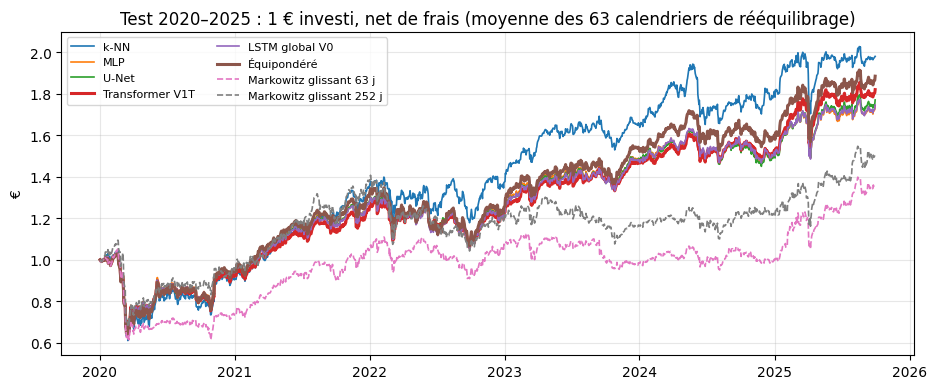

In [33]:
fig, ax = plt.subplots(figsize=(11, 4.2))
for nom in results:
    if nom == "Oracle":
        continue
    mesures, richesse = results[nom]
    epaisseur = 1.2
    if nom == "Équipondéré" or nom == "Transformer V1T":           # les deux courbes à comparer en priorité
        epaisseur = 2.2
    style = "-"
    if "Markowitz" in nom:                                          # Markowitz en pointillés
        style = "--"
    ax.plot(richesse, lw=epaisseur, ls=style, label=nom)

ax.set_title("Test 2020–2025 : 1 € investi, net de frais (moyenne des 63 calendriers de rééquilibrage)")
ax.set_ylabel("€")
ax.grid(alpha=0.3)
ax.legend(ncol=2, fontsize=8)
plt.show()

### Régularité des allocations

Un bon modèle ne doit pas seulement performer : il doit proposer des portefeuilles **stables**, sinon les frais mangent la performance. On compare les poids de l'oracle, du Markowitz glissant et du réseau retenu sur le test.

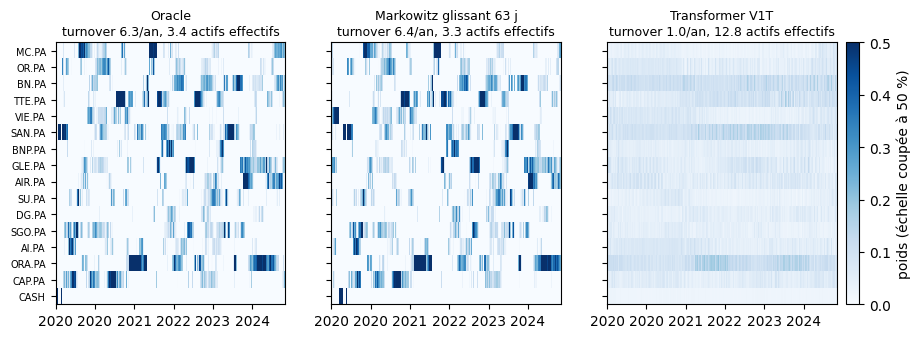

In [34]:
noms = ["Oracle", "Markowitz glissant 63 j", "Transformer V1T"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for i in range(3):
    ax, nom = axes[i], noms[i]
    # une ligne par actif, une colonne par date ; plus c'est foncé, plus le poids est grand
    im = ax.imshow(W_all[nom].T, aspect="auto", cmap="Blues", vmin=0, vmax=0.5, interpolation="nearest")
    turnover = table.loc[nom, "turnover_an"]
    n_eff = table.loc[nom, "n_eff"]
    ax.set_title(f"{nom}\nturnover {turnover:.1f}/an, {n_eff:.1f} actifs effectifs", fontsize=9)
    ax.set_xticks(np.arange(0, len(te), 252), X.index[te][::252].year)   # une graduation par année

axes[0].set_yticks(range(16), ASSETS, fontsize=7)
fig.colorbar(im, ax=axes, label="poids (échelle coupée à 50 %)", pad=0.01)
plt.show()

**Lecture.**
- **L'oracle est hors d'atteinte** : Sharpe de 3,3 contre 0,57 pour l'équipondéré. Il existe une excellente allocation chaque trimestre, mais elle dépend des rendements futurs.
- **Recopier l'ancienne allocation optimale ne marche pas** : le Markowitz glissant est aussi concentré et instable que l'oracle (3 actifs effectifs, portefeuille renouvelé 4 à 6 fois par an), pour un Sharpe de 0,28 (63 jours) et 0,37 (252 jours). L'allocation optimale d'un trimestre ne dit presque rien de la suivante : c'est l'erreur d'estimation classique de Markowitz.
- **Le k-NN a le meilleur rendement (12,3 % par an), mais pas le meilleur rapport rendement / risque** : même Sharpe que l'équipondéré (0,58), la plus forte perte maximale des modèles (−42 %), un portefeuille renouvelé 4,4 fois par an et un résultat qui dépend fortement du jour de rééquilibrage (±0,11).
- **Les réseaux apprennent la prudence** : 13 à 15 actifs effectifs, un turnover de 0,3 à 1 par an. Le MLP, le U-Net et V0 restent sous l'équipondéré (Sharpe 0,52 à 0,53).
- **Le Transformer partagé est le seul réseau qui imite nettement mieux l'oracle** (entropie croisée 2,69, contre 2,79 pour la meilleure allocation constante) et le seul au niveau de l'équipondéré (Sharpe 0,58 contre 0,57), avec la plus faible perte maximale (−35 % contre −38 %).
- **Aucun écart de Sharpe n'est significatif**, hors oracle : sur 6 ans de test, un Sharpe n'est mesuré qu'à environ ±0,4 près.

## 8. Que regarde le modèle ? Analyse SHAP du Transformer

Dans V1T, le score d'une action ne dépend que de **sa propre séquence** (52 semaines × 2 canaux) ; le softmax ne fait ensuite que comparer les scores. On explique donc la fonction « séquence d'une action → score », avec `shap.GradientExplainer` : chaque valeur SHAP mesure de combien un rendement hebdomadaire donné fait monter ou baisser le score de l'action, par rapport à une séquence de référence tirée du train.

In [35]:
fam, conf = RETENUS["Transformer V1T"]
fichier = RES / "shap_v1t.npz"
if fichier.exists() and not RERUN:                      # valeurs déjà calculées
    sauvegarde = np.load(fichier)
    sv, xe, score = sauvegarde["sv"], sauvegarde["xe"], sauvegarde["score"]
else:
    import shap
    # le Transformer final (graine 0), relu depuis son checkpoint de la partie 7
    model, xs, _ = fit(CONFIGS[fam][conf], FINAL[0], epochs=nombre_epoques(fam, conf), seed=0,
                       ckpt=chemin_final("Transformer V1T", conf, 0))

    class ActionScore(nn.Module):                       # séquence d'une action (n, 52, 2) → son score avant softmax
        def __init__(self, m):
            super().__init__()
            self.m = m
        def forward(self, s):
            return self.m.score(self.m.encode(s))

    def sample(i, n):                                   # n séquences (date, action) tirées au hasard parmi les dates i
        s = xs[0][i].reshape(-1, 52, 2)
        return s[torch.randperm(len(s))[:n]]

    torch.manual_seed(0)                               # tirages de sample() et de GradientExplainer reproductibles
    np.random.seed(0)
    f = ActionScore(model).eval()
    background = sample(FINAL[0], 200)                 # référence : 200 trajectoires du train
    explained = sample(FINAL[1], 1000)                 # à expliquer : 1 000 trajectoires du test
    sv = np.squeeze(np.array(shap.GradientExplainer(f, background).shap_values(explained)))   # (1000, 52, 2)
    xe = explained.numpy()
    with torch.no_grad():
        score = f(explained).squeeze(-1).numpy()        # score de chaque séquence expliquée
    np.savez(fichier, sv=sv, xe=xe, score=score)

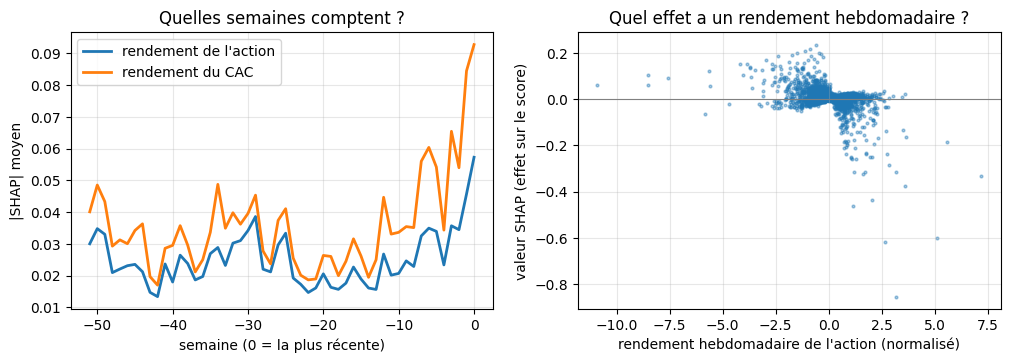

Corrélation du score avec la volatilité de l'action sur 1 an : -0.20
Corrélation du score avec sa performance sur 1 an            : -0.09
Part de l'importance SHAP portée par le canal CAC             : 59%


In [36]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.6))
for c, nom in enumerate(["rendement de l'action", "rendement du CAC"]):
    a.plot(np.arange(-51, 1), np.abs(sv[:, :, c]).mean(0), lw=2, label=nom)
a.set_title("Quelles semaines comptent ?")
a.set_xlabel("semaine (0 = la plus récente)")
a.set_ylabel("|SHAP| moyen")
a.legend()
a.grid(alpha=0.3)
b.scatter(xe[:, :, 0].ravel()[::20], sv[:, :, 0].ravel()[::20], s=4, alpha=0.4)
b.axhline(0, color="gray", lw=0.8)
b.set_title("Quel effet a un rendement hebdomadaire ?")
b.set_xlabel("rendement hebdomadaire de l'action (normalisé)")
b.set_ylabel("valeur SHAP (effet sur le score)")
b.grid(alpha=0.3)
plt.show()

# lien entre le score d'une action et deux statistiques simples de sa trajectoire
print(f"Corrélation du score avec la volatilité de l'action sur 1 an : {np.corrcoef(score, xe[:, :, 0].std(1))[0, 1]:+.2f}")
print(f"Corrélation du score avec sa performance sur 1 an            : {np.corrcoef(score, xe[:, :, 0].sum(1))[0, 1]:+.2f}")
print(f"Part de l'importance SHAP portée par le canal CAC             : {np.abs(sv[:, :, 1]).sum() / np.abs(sv).sum():.0%}")

**Lecture.**
- **Graphique de gauche** : l'importance est concentrée sur les 2 à 3 dernières semaines (la plus récente pèse environ 4 à 5 fois le minimum), mais elle ne s'annule jamais : le modèle lit toute l'année, avec un poids plus fort sur le récent. Les pics isolés viennent de quelques semaines extrêmes de l'échantillon, pas d'une saisonnalité. Le canal **CAC** porte 59 % de l'importance, au-dessus de l'action presque chaque semaine.
- **Graphique de droite** : la relation est **décroissante et asymétrique**, sans forme en U. Les fortes hausses hebdomadaires (au-delà de +1 écart-type) font nettement baisser le score (jusqu'à −0,85), alors que les baisses l'affectent peu, voire le relèvent légèrement. Le modèle ne récompense donc pas le momentum : il **pénalise les actions qui viennent de bondir**.
- **Les corrélations** confirment une règle réelle mais faible : score et volatilité à 1 an **−0,20**, score et performance à 1 an **−0,09** (quasi nul).

**Deux précautions.**
- **Le poids du CAC est surestimé par SHAP** : le canal CAC est le même pour les 15 actions à une date donnée, donc une partie de son effet s'ajoute au score de toutes les actions et s'annule dans le softmax. Son rôle utile est de permettre de mesurer le lien de chaque action au marché, ce que confirme l'ablation (moins bien sans le canal CAC).
- **Le poids plus fort sur les dernières semaines n'est pas ce qui fait la performance** : sans encodage de position, le modèle ne peut plus distinguer les semaines récentes, et il fait aussi bien (ablation).

Le réseau note donc les actions sur leur **profil de risque** et n'essaie pas de deviner les gagnants : le risque est persistant, les rendements ne le sont pas. C'est cohérent avec des portefeuilles diversifiés, légèrement inclinés vers les actions peu volatiles, et un Sharpe proche de l'équipondéré. Cette lecture décrit ce que le modèle utilise (1 000 séquences du test, une seule graine), pas une vérité de marché.

## 9. Conclusion

**Ce que nous avons fait.** Un jeu de données contrôlé (160 features, cible oracle à 63 jours, aucune fuite du futur), un protocole unique (validation croisée walk-forward purgée, test final utilisé une seule fois, backtest avec frais), et quatre approches comparées sur la même base : k-NN, MLP, U-Net, réseaux séquentiels.

**Ce que nous trouvons.**
1. **L'oracle est très difficile à imiter.** Il est concentré, change presque entièrement d'un trimestre à l'autre, et dépend des rendements futurs. La meilleure prédiction au sens de l'entropie croisée reste proche de l'allocation moyenne : tous les réseaux sortent des portefeuilles diversifiés.
2. **L'architecture compte plus que la quantité d'information.** Partager un même encodeur entre les actions, et résumer toute l'année plutôt que les derniers jours, améliore l'imitation de l'oracle. Ajouter de la capacité ne change rien ; pour le MLP, retirer les 150 variables par action ne fait rien perdre, et le meilleur MLP ne lit que les 10 variables de régime de marché. Pour le Transformer, l'ablation montre que **l'ordre des semaines n'apporte rien** et que les features n'ajoutent rien à la trajectoire, alors que le rendement du CAC aide : ce qui compte, ce sont des statistiques sur l'année et le lien au marché, pas la chronologie.
3. **Mieux imiter l'oracle ne suffit pas à battre l'équipondéré.** Les Sharpe des réseaux et de l'équipondéré sont du même ordre, et leurs écarts sont inférieurs à l'incertitude de mesure. C'est le résultat classique de DeMiguel, Garlappi et Uppal (2009) : l'erreur d'estimation coûte ce que l'optimisation rapporte.
4. **Les réseaux font nettement mieux que le Markowitz « naïf »** (glissant) et que le k-NN en régularité : peu de transactions, pas de concentration extrême.
5. **Ce que le modèle apprend est interprétable** : il note les actions sur leur profil de risque passé, la seule partie réellement persistante du problème.
6. **Les pertes proposées par le sujet ne font pas mieux que l'entropie croisée** (testées sur le MLP, le U-Net et le Transformer). Avec la MSE, l'imitation de l'oracle est équivalente (MLP) ou nettement moins bonne (U-Net, Transformer), et le Sharpe n'est jamais nettement meilleur. La maximisation directe du Sharpe n'améliore pas le Sharpe de validation : le Sharpe d'un lot est trop bruité pour guider l'apprentissage.

**Limites et pistes.** Environ 55 trimestres indépendants seulement, une seule graine en validation croisée, 15 actions, un seul échantillon de test de 6 ans. Pistes : une cible plus prévisible (portefeuille de variance minimale), un mélange équipondéré / modèle, un univers plus large pour multiplier les exemples vus par l'encodeur partagé.